# 01 — Data Collection & Exploration

**CSC17104 – Programming for Data Science · Đồ án cuối kỳ**
Dataset: *Coffee Quality with Locations of Origin* (Kaggle)

| MSSV | Họ tên | Phụ trách trong notebook |
|---|---|---|
| 24120053 | Đặng Ngọc Hoàng | 3.1 Data collection |
| 23120361 | Đức Thịnh | 3.2.1 Overview · 3.2.2 Numerical · 3.2.4 Missing |
| 23120311 | Tùng Hiếu | 3.2.3 Categorical · 3.2.5 Relationships · 3.2.6 Summary |

**Mục lục**

- 0\. Môi trường code & thư viện
- 3.1. Data collection
    - Đọc dữ liệu
    - 3.1.1. Subject
    - 3.1.2. Source
    - 3.1.3. License
    - 3.1.4. Collection method
    - 3.1.5. Motivation
    - 3.1.6. Các file dữ liệu và cách nhóm sử dụng
- 3.2. Data exploration
    - 3.2.1. Overview
    - 3.2.2. Numerical columns
    - 3.2.3. Categorical columns
    - 3.2.4. Missing data
    - 3.2.5. Relationships
    - 3.2.6. Summary
- Tài liệu tham khảo

> **Nguyên tắc: Reproducibility.** Mọi `import` nằm ở phần đầu notebook. Mọi đường dẫn lấy từ `src/config.py` (đường dẫn **tương đối**), không viết `D:\...` hay `/home/...`. Mỗi nhận định trong phần chữ phải có **một ô code chứng minh bằng dữ liệu thật** ngay phía trên hoặc phía dưới.

**Quy ước trong notebook**
- `# YOUR CODE HERE`: ô code cần tự viết.
- `# TEST`: ô kiểm tra, viết `assert` để chắc kết quả đúng.
- ✍️ **YOUR ANSWER HERE**: ô Markdown cần tự viết câu trả lời, dựa trên output của code.

---
## 0. Môi trường code & thư viện


### Kiểm tra xem Notebook có đang chạy đúng env không?


In [1]:
import sys
sys.executable

'D:\\anaconda\\envs\\coffee\\python.exe'

Kết quả mong đợi: đường dẫn kết thúc bằng `.../envs/coffee/bin/python`. 

### Import các thư viện

In [2]:
import sys
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

NOTEBOOK_CWD = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_CWD.parent if NOTEBOOK_CWD.name == "notebooks" else NOTEBOOK_CWD
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.config import RAW, SCORE_COLS, RANDOM_STATE, add_total_score
from src.labels import CAT_COLS, COUNTRY_ALIASES, group_rare, normalize_labels

pd.set_option("display.max_columns", None) 

%matplotlib inline

In [3]:
import matplotlib

print("numpy     :", np.__version__)
print("pandas    :", pd.__version__)
print("matplotlib:", matplotlib.__version__)

numpy     : 1.26.4
pandas    : 2.1.4
matplotlib: 3.8.4


In [4]:
# TEST
def major_minor(version):
    """'2.1.1' -> '2.1'"""
    return ".".join(version.split(".")[:2])

assert major_minor(np.__version__) == "1.26", f"numpy {np.__version__} khác environment.yml"
assert major_minor(pd.__version__) == "2.1", f"pandas {pd.__version__} khác environment.yml"
assert major_minor(matplotlib.__version__) == "3.8", f"matplotlib {matplotlib.__version__} khác environment.yml"
print("Môi trường OK")

Môi trường OK


---
## 3.1. Data collection

### Đọc dữ liệu

Thư mục `data/raw/` có 3 file CSV tải từ Kaggle. Đọc cả 3 file vào 3 DataFrame:
- `df`: file chính `Coffee_Qlty.csv`
- `df_country`: `Coffee_Qlty_By_Country.csv`
- `df_continent`: `Coffee_Qlty_By_Continent.csv`

In [5]:
MAIN_FILE      = RAW / "Coffee_Qlty.csv"
COUNTRY_FILE   = RAW / "Coffee_Qlty_By_Country.csv"
CONTINENT_FILE = RAW / "Coffee_Qlty_By_Continent.csv"

df           = pd.read_csv(MAIN_FILE, keep_default_na=False, na_values=[""])
df_country   = pd.read_csv(COUNTRY_FILE)
df_continent = pd.read_csv(CONTINENT_FILE)

In [6]:
for path, table in [(MAIN_FILE, df), (COUNTRY_FILE, df_country), (CONTINENT_FILE, df_continent)]:
    n_rows, n_cols = table.shape
    print(f"{path.name:<32} {n_rows:>6,} dòng × {n_cols:>3} cột")

Coffee_Qlty.csv                   1,339 dòng ×  22 cột
Coffee_Qlty_By_Country.csv           34 dòng ×  15 cột
Coffee_Qlty_By_Continent.csv          5 dòng ×  15 cột


In [7]:
assert len(sorted(RAW.glob("*.csv"))) == 3, "data/raw/ phải có đúng 3 file CSV"
assert df.shape == (1339, 22), f"df có shape {df.shape}, khác 1.339 × 22"
assert df_country.shape[0] < df.shape[0], "file By_Country phải ít dòng hơn file chính (1 dòng = 1 quốc gia)"
assert df_continent.shape[0] < df_country.shape[0], "số châu lục phải ít hơn số quốc gia"
print("Đọc dữ liệu OK")

Đọc dữ liệu OK


In [8]:
# REC_ID chạy từ 0 nên giá trị lớn nhất = số dòng - 1
print(df["REC_ID"].min(), df["REC_ID"].max(), df["REC_ID"].nunique())

0 1338 1339


Trang Kaggle hiển thị REC_ID từ 0 đến 1338, dễ đọc nhầm thành 1.338 dòng. Vì REC_ID bắt đầu từ 0, dữ liệu thực tế có 1.339 dòng, mỗi REC_ID là duy nhất.

### 3.1.1. Subject

**1. CQI là ai?**  
Coffee Quality Institute (CQI) là tổ chức phi lợi nhuận của Mỹ, hướng tới nâng cao chất lượng cà phê và sinh kế của người trồng. CQI quản lý chương trình **Q Grader**: chứng nhận những người nếm thử cà phê chuyên nghiệp (*cupper*) sau khi họ vượt qua một loạt bài kiểm tra về khứu giác, vị giác và phân loại hạt [2].

**2. Cupping là gì?**  
Cupping là quy trình chuẩn để nếm và chấm điểm cà phê theo giao thức của Specialty Coffee Association (SCA) [3]. Mẫu cà phê nhân xanh được rang nhẹ, xay, ngâm với nước nóng; Q Grader ngửi, nếm rồi chấm từng thuộc tính cảm quan trên thang 0–10:

- *Aroma, Flavor, Aftertaste, Acidity, Body, Balance*: chấm theo cảm nhận của chuyên gia.
- *Uniformity, Clean Cup, Sweetness*: chấm theo số cốc đạt (mỗi mẫu nếm 5 cốc, mỗi cốc đạt được 2 điểm), vì vậy 3 cột này thường bằng 10.
- Bảng chấm gốc còn có điểm tổng thể của cupper. Tổng các thuộc tính trừ điểm lỗi cho ra Total Cup Points trên thang 100; lô đạt từ 80 điểm được xem là *specialty* [3].

**3. Các chỉ số vật lý của hạt nhân xanh**

- *Moisture*: độ ẩm của hạt; khoảng 10–12% thường được xem là phù hợp để bảo quản.
- *Category One Defects*: lỗi nặng (hạt đen hoàn toàn, chua hoàn toàn…).
- *Category Two Defects*: lỗi nhẹ hơn (hạt vỡ, sâu đục…). Hai loại lỗi này được đếm trên một mẫu hạt nhân xanh.
- *Quakers*: hạt chưa chín, sau khi rang có màu nhạt bất thường và làm giảm chất lượng vị.

**4. Liên hệ với bộ dữ liệu của nhóm**
Mỗi dòng là kết quả chấm của một lô cà phê. Bộ dữ liệu chỉ có 9 thuộc tính cảm quan, không có *Overall* và *Total Cup Points*, nên nhóm tự tạo biến `total_9` (tổng 9 thuộc tính) làm thước đo chất lượng tổng hợp.

In [9]:
#Xem ngẫu nhiên 3 dòng
df.sample(3, random_state=RANDOM_STATE)

,REC_ID,Species,Continent.of.Origin,Country.of.Origin,Harvest.Year,Expiration,Variety,Color,Processing.Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Moisture,Quakers,Category.One.Defects,Category.Two.Defects
394,394,Arabica,Asia,Thailand,NaN,04/13/11,Peaberry,NaN,NaN,7.58,7.25,7.50,7.92,7.92,7.42,10.0,10.0,10.0,0.11,0,0,0
881,881,Arabica,Asia,Indonesia,2013.0,05/23/15,Sumatra,Bluish-Green,Semi-washed / Semi-pulped,7.17,7.42,7.33,7.42,7.33,7.42,10.0,10.0,10.0,0.11,0,0,0
358,358,Arabica,Asia,Indonesia,2015.0,09/13/16,Sumatra,Bluish-Green,Semi-washed / Semi-pulped,7.25,7.67,7.58,7.92,7.83,7.58,10.0,10.0,10.0,0.13,0,0,8


In [10]:
#Kiểm tra cột REC_ID có giá trị duy nhất không
n_rows   = len(df)
n_unique = df["REC_ID"].nunique()

print("Số dòng            :", n_rows)
print("Số REC_ID khác nhau:", n_unique)
print("REC_ID duy nhất?   :", df["REC_ID"].is_unique)

Số dòng            : 1339
Số REC_ID khác nhau: 1339
REC_ID duy nhất?   : True


In [11]:
# TEST
assert df["REC_ID"].is_unique, "Có REC_ID bị lặp → một dòng không tương ứng một lô"
assert df["REC_ID"].nunique() == len(df), "Số REC_ID khác số dòng"
assert df["REC_ID"].notna().all(), "Có dòng thiếu REC_ID"
print("REC_ID là duy nhất")

REC_ID là duy nhất


#### Dữ liệu gồm những nhóm thông tin nào?

Chia 22 cột thành các nhóm theo **vai trò**:

| Nhóm | Các cột | Ý nghĩa | Vai trò trong phân tích |
|:---|:---|:---|:---|
| Định danh | `REC_ID` | Mã lô trong cơ sở dữ liệu CQI | Chỉ để phân biệt lô, không phân tích |
| Xuất xứ | `Species`, `Continent.of.Origin`, `Country.of.Origin` | Loài cà phê, châu lục, quốc gia | Biến phân loại để so sánh nhóm |
| Thông tin lô | `Harvest.Year`, `Expiration`, `Variety`, `Color`, `Processing.Method` | Năm thu hoạch, hạn chứng nhận, giống, màu hạt, cách sơ chế | Biến phân loại / thời gian |
| Cảm quan | `Aroma`, `Flavor`, `Aftertaste`, `Acidity`, `Body`, `Balance`, `Uniformity`, `Clean.Cup`, `Sweetness` | 9 thuộc tính do Q Grader chấm, thang 0–10 | Kết quả chất lượng, dùng tạo `total_9` |
| Vật lý / lỗi hạt | `Moisture`, `Quakers`, `Category.One.Defects`, `Category.Two.Defects` | Độ ẩm, hạt chưa chín, số lỗi nặng, số lỗi nhẹ | Đo trên hạt nhân xanh, trước khi cupping |

In [12]:
#Chia nhóm và in bảng
column_groups = {
    "Định danh":        ["REC_ID"],
    "Xuất xứ":          ["Species", "Continent.of.Origin", "Country.of.Origin"],
    "Thông tin lô":     ["Harvest.Year", "Expiration", "Variety", "Color", "Processing.Method"],
    "Cảm quan":         SCORE_COLS,
    "Vật lý / lỗi hạt": ["Moisture", "Quakers", "Category.One.Defects", "Category.Two.Defects"],
}

group_table = pd.DataFrame({
    "Nhóm":    list(column_groups.keys()),
    "Số cột":  [len(cols) for cols in column_groups.values()],
    "Các cột": [", ".join(cols) for cols in column_groups.values()],
})
group_table

,Nhóm,Số cột,Các cột
0,Định danh,1,REC_ID
1,Xuất xứ,3,"Species, Continent.of.Origin, Country.of.Origin"
2,Thông tin lô,5,"Harvest.Year, Expiration, Variety, Color, Proc..."
3,Cảm quan,9,"Aroma, Flavor, Aftertaste, Acidity, Body, Bala..."
4,Vật lý / lỗi hạt,4,"Moisture, Quakers, Category.One.Defects, Categ..."


In [13]:
# TEST
all_grouped = [col for cols in column_groups.values() for col in cols]

assert len(all_grouped) == 22, f"Đang có {len(all_grouped)} cột trong các nhóm, cần 22"
assert len(all_grouped) == len(set(all_grouped)), "Có cột nằm ở 2 nhóm"
assert set(all_grouped) == set(df.columns), (
    f"Thiếu trong nhóm: {set(df.columns) - set(all_grouped)} | "
    f"Không có trong df: {set(all_grouped) - set(df.columns)}"
)
print("Chia nhóm cột OK")

Chia nhóm cột OK


**Tóm tắt mục 3.1.1:**

- **Chủ đề:** dữ liệu ghi lại kết quả đánh giá chất lượng của 1.339 lô cà phê nhân xanh do Coffee Quality Institute (CQI) chấm điểm. CQI là tổ chức phi lợi nhuận đào tạo và chứng nhận các chuyên gia nếm thử (*Q Grader*); họ chấm từng lô theo quy trình *cupping* chuẩn của Specialty Coffee Association (SCA).
- **Một dòng chứa nội dung gì:** mỗi dòng là một lô cà phê, định danh bằng `REC_ID` (đã kiểm tra: 1.339 giá trị có `REC_ID` là duy nhất = 1.339 dòng).
- **Dữ liệu gồm 5 nhóm thông tin:**
    - *Định danh* (1 cột): mã lô.
    - *Xuất xứ* (3 cột): loài, châu lục, quốc gia.
    - *Thông tin lô* (5 cột): năm thu hoạch, hạn chứng nhận, giống, màu hạt, phương pháp sơ chế.
    - *Cảm quan* (9 cột): Aroma, Flavor, Aftertaste, Acidity, Body, Balance, Uniformity, Clean Cup, Sweetness, chấm trên thang 0–10.
    - *Vật lý / lỗi hạt* (4 cột): độ ẩm, số hạt chưa chín (quakers), số lỗi nặng, số lỗi nhẹ.
- **Bối cảnh thực tế:** kết quả chấm của CQI là căn cứ để xác định một lô có đạt chuẩn cà phê đặc sản (*specialty*) hay không. Thông tin này được người trồng dùng để cải thiện khâu sơ chế, và được nhà nhập khẩu, nhà rang xay dùng để chọn nguồn hàng và thương lượng giá.
- **Lưu ý:** dữ liệu không có điểm tổng thể của cupper (*Overall*) và điểm tổng *Total Cup Points*, nên nhóm tự tạo biến `total_9` = tổng 9 thuộc tính cảm quan làm thước đo chất lượng tổng hợp.

### 3.1.2. Source

| Mục | Thông tin |
|:---|:---|
| **Platform** | Kaggle |
| **URL** | https://www.kaggle.com/datasets/adampq/coffee-quality-with-locations-of-origin |
| **Tác giả trên Kaggle** | RealDealAdamP (`adampq`) |
| **Nguồn gốc dữ liệu** | Cơ sở dữ liệu của Coffee Quality Institute (CQI): https://database.coffeeinstitute.org |
| **Ngày công bố trên Kaggle** | 31/03/2024 (Version 1 – *Initial release*, chưa cập nhật lần nào) |
| **Phiên bản dataset** | Version 1 |
| **Tần suất cập nhật** | Never |
| **Ngày nhóm tải về** | 01/11/2026 |

#### Kiểm tra tính toàn vẹn của dữ liệu

**MD5** là một chuỗi 32 ký tự tính từ nội dung file: chỉ cần file khác đi một byte, mã MD5 sẽ khác hoàn toàn. Ai tải lại dữ liệu theo README chỉ cần so mã MD5 với bảng dưới đây là biết mình có dùng đúng bản dữ liệu của nhóm hay không.

In [14]:
def md5_of(path, chunk_size=8192):
    """Tính mã MD5 của một file (đọc theo từng khối để không tốn bộ nhớ)."""
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

file_info = pd.DataFrame([
    {"file": p.name,
     "size_kb": round(p.stat().st_size / 1024, 1),
     "md5": md5_of(p)}
    for p in sorted(RAW.glob("*.csv"))
])
file_info

,file,size_kb,md5
0,Coffee_Qlty.csv,166.6,183955d1a03c9d7447cf658e9cff0f45
1,Coffee_Qlty_By_Continent.csv,1.3,b5befb87b0d98c8b75d3263afa86fc91
2,Coffee_Qlty_By_Country.csv,5.5,625485a31a724517d132cfc4741e3f4f


In [15]:
print("| File | Kích thước (KB) | MD5 |")
print("|:---|---:|:---|")
for _, row in file_info.iterrows():
    print(f"| `{row.file}` | {row.size_kb} | `{row.md5}` |")

| File | Kích thước (KB) | MD5 |
|:---|---:|:---|
| `Coffee_Qlty.csv` | 166.6 | `183955d1a03c9d7447cf658e9cff0f45` |
| `Coffee_Qlty_By_Continent.csv` | 1.3 | `b5befb87b0d98c8b75d3263afa86fc91` |
| `Coffee_Qlty_By_Country.csv` | 5.5 | `625485a31a724517d132cfc4741e3f4f` |


Bảng mã MD5 ở trên đã được ghi vào `README.md` (mục *Dataset*). Khi tải lại dữ liệu, chạy ô trên và so sánh: nếu cả 3 mã MD5 trùng khớp thì dữ liệu giống hệt bản nhóm đã dùng.

### 3.1.3. License

Trang Kaggle của bộ dữ liệu ghi giấy phép **CC BY-SA 4.0** (Creative Commons Attribution-ShareAlike 4.0 International) [3]. Giấy phép cho phép **sao chép, chia sẻ và chỉnh sửa** dữ liệu cho mọi mục đích, với 2 điều kiện:

- **BY (Attribution):** phải ghi tên tác giả và nguồn, kèm đường dẫn tới giấy phép, và nói rõ nếu đã chỉnh sửa dữ liệu.
- **SA (ShareAlike):** nếu chỉnh sửa hoặc tạo sản phẩm mới dựa trên dữ liệu rồi chia sẻ lại, sản phẩm đó phải dùng cùng giấy phép CC BY-SA 4.0, không được thêm điều khoản hạn chế người khác.

#### Nguồn gốc giấy phép qua các tầng dữ liệu

| Tầng | Nguồn | Giấy phép |
|:---|:---|:---|
| Bộ nhóm dùng | Kaggle `adampq/coffee-quality-with-locations-of-origin` | CC BY-SA 4.0 |
| Nguồn trung gian | Kaggle `volpatto/coffee-quality-database-from-cqi` | Open Database License (ODbL) |
| Nguồn trung gian | Kaggle `fatihb/coffee-quality-data-cqi` | "Other", phần mô tả không nêu giấy phép cụ thể |
| Code scrape | GitHub `jldbc/coffee-quality-database` | MIT (áp dụng cho mã nguồn, không phải dữ liệu) |
| Dữ liệu gốc | Coffee Quality Institute | Nhóm không tìm thấy điều khoản công khai về tái sử dụng dữ liệu |

#### Hệ quả với nhóm

- **Ghi nguồn:** ghi đầy đủ tác giả, link Kaggle, nguồn gốc CQI và giấy phép CC BY-SA 4.0 trong `README.md`, notebook và slide thuyết trình.
- **Dữ liệu đã xử lý** (`data/processed/`): ghi rõ các bước chỉnh sửa (làm sạch, tạo biến `total_9`, nối dữ liệu FAOSTAT). 
- **Không commit dữ liệu gốc lên GitHub:** Người dùng tự tải dữ liệu theo README.
- **Dữ liệu gốc CQI:** Nhóm chỉ dùng dữ liệu cho mục đích học tập và ghi nguồn đầy đủ tới CQI.

**Kết luận:** Bộ dữ liệu được phép sử dụng cho đồ án theo giấy phép **CC BY-SA 4.0**, với điều kiện nhóm ghi nguồn đầy đủ (tác giả Kaggle, CQI, giấy phép) và nếu chia sẻ lại dữ liệu đã chỉnh sửa thì phải dùng cùng giấy phép. Vì dữ liệu gốc của CQI không có giấy phép công khai rõ ràng, nhóm chỉ sử dụng dữ liệu cho mục đích học tập và không phát hành lại dữ liệu gốc.

### 3.1.4. Collection method

#### (a) Thu thập bằng cách nào?

Dữ liệu được thu thập tự động bằng script từ cơ sở dữ liệu công khai của CQI (https://database.coffeeinstitute.org), rồi đi qua nhiều tầng trước khi tới bộ nhóm dùng:

| Thời gian | Bước | Nguồn |
|:---|:---|:---|
| 01/2018 | J. LeDoux viết script Python scrape các trang đánh giá trên website CQI, thu được khoảng 1.340 lô (cả Arabica và Robusta) | GitHub `jldbc/coffee-quality-database` [4] |
| 12/2019 | D. Volpatto đưa bộ dữ liệu này lên Kaggle | Kaggle `volpatto` [6] |
| 05/2023 | F. Boyar sửa lại script cho phù hợp website mới và scrape lại, chỉ lấy Arabica | Kaggle `fatihb` [7] |
| 31/03/2024 | RealDealAdamP tổng hợp, chỉnh sửa từ các bộ trên và công bố bộ *Coffee Quality with Locations of Origin* | Kaggle `adampq` [1] |

Nguồn: mục *Provenance → Collection Methodology* trên trang Kaggle [1]: *"This is a modified version of the aforementioned Kaggle source data sets. Python scrapping scripts were used in order to collect data from https://database.coffeeinstitute.org/"*.

#### (b) Quần thể: những lô cà phê nào có mặt trong dữ liệu?

In [16]:
# Đếm theo loài
species_counts = df["Species"].value_counts(dropna=False)

species_table = pd.DataFrame({
    "Số lô": species_counts,
    "Tỷ lệ (%)": (species_counts / len(df) * 100).round(2),
})
species_table

,Số lô,Tỷ lệ (%)
Species,,
Arabica,1311,97.91
Robusta,28,2.09


In [17]:
# Đếm theo châu lục và số quốc gia
continent_counts = df["Continent.of.Origin"].value_counts(dropna=False)

continent_table = pd.DataFrame({
    "Số lô": continent_counts,
    "Tỷ lệ (%)": (continent_counts / len(df) * 100).round(2),
})
display(continent_table)

n_countries = df["Country.of.Origin"].nunique()
n_missing_country = df["Country.of.Origin"].isna().sum()
print(f"Số quốc gia khác nhau: {n_countries}")
print(f"Số lô thiếu quốc gia : {n_missing_country}")

,Số lô,Tỷ lệ (%)
Continent.of.Origin,,
North America,665,49.66
South America,328,24.50
Asia,182,13.59
Africa,162,12.10
Oceania,1,0.07
NaN,1,0.07


Số quốc gia khác nhau: 34
Số lô thiếu quốc gia : 1


In [18]:
# TEST
assert np.isclose(species_table["Tỷ lệ (%)"].sum(), 100, atol=0.05), "Tổng tỷ lệ theo loài phải bằng 100%"

n_with_continent = df["Continent.of.Origin"].notna().sum()
n_missing_continent = df["Continent.of.Origin"].isna().sum()
assert n_with_continent + n_missing_continent == len(df), "Số lô theo châu lục + số lô thiếu châu lục phải bằng tổng số dòng"
assert continent_table["Số lô"].sum() == len(df), "Bảng châu lục (kể cả NaN) phải đếm đủ mọi dòng"

print("Quần thể OK")

Quần thể OK


#### (c) Giai đoạn: dữ liệu trải từ năm nào đến năm nào?

Có 2 cột thời gian:
- `Harvest.Year`: năm thu hoạch của lô.
- `Expiration`: ngày hết hạn chứng nhận chất lượng của lô (gần với thời điểm được chấm).

In [19]:
# Năm thu hoạch
harvest_year = pd.to_numeric(df["Harvest.Year"], errors="coerce").astype("Int64")

n_missing_year = harvest_year.isna().sum()
print(f"Số lô thiếu năm thu hoạch: {n_missing_year} ({n_missing_year / len(df):.1%})")
print(f"Năm sớm nhất: {harvest_year.min()} | Năm muộn nhất: {harvest_year.max()}")

lots_per_year = harvest_year.value_counts().sort_index()
lots_per_year.to_frame("Số lô")

Số lô thiếu năm thu hoạch: 60 (4.5%)
Năm sớm nhất: 2009 | Năm muộn nhất: 2018


,Số lô
Harvest.Year,
2009,20
2010,30
2011,35
2012,354
2013,210
2014,252
2015,157
2016,131
2017,89


In [20]:
# Ngày hết hạn chứng nhận
expiration = pd.to_datetime(df["Expiration"], format="%m/%d/%y", errors="coerce")

n_bad_date = expiration.isna().sum() - df["Expiration"].isna().sum()
print(f"Ngày sớm nhất : {expiration.min():%d/%m/%Y}")
print(f"Ngày muộn nhất: {expiration.max():%d/%m/%Y}")
print(f"Số giá trị không đọc được: {n_bad_date}")

Ngày sớm nhất : 09/04/2011
Ngày muộn nhất: 19/01/2019
Số giá trị không đọc được: 0


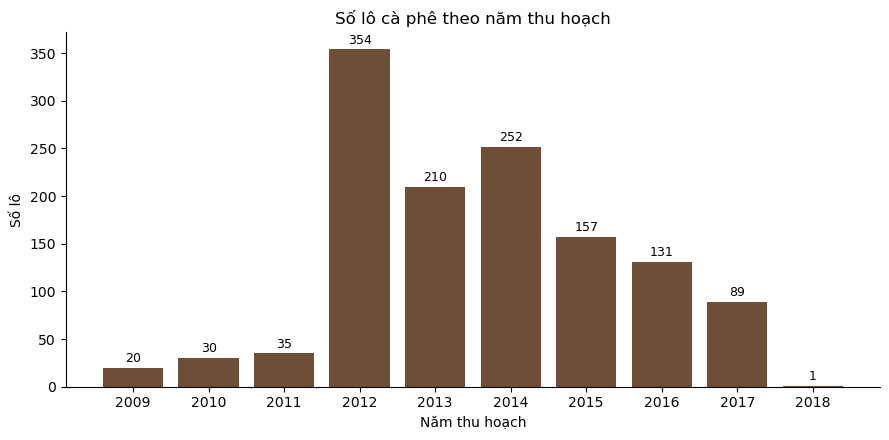

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(lots_per_year.index.astype(str), lots_per_year.values, color="#6F4E37")

ax.bar_label(bars, padding=2, fontsize=9)          # ghi số lô lên đầu mỗi cột
ax.set_title("Số lô cà phê theo năm thu hoạch")
ax.set_xlabel("Năm thu hoạch")
ax.set_ylabel("Số lô")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Nhận xét — giai đoạn:**
- Năm thu hoạch trải từ **2009 đến 2018**; có **60 lô (4,5%) thiếu năm thu hoạch**.
- Phần lớn lô tập trung trong giai đoạn **2012–2016** (chiếm khoảng 86,3% số lô có năm, tức 1.104/1.279 lô), nhiều nhất là năm **2012** với 354 lô.
- Các năm đầu (**2009–2011**: 20, 30, 35 lô) và năm cuối (**2018**) có rất ít lô (năm ít nhất chỉ 1 lô).
- Cột `Expiration` trải từ **09/04/2011 đến 19/01/2019**. Vì chứng nhận CQI có hạn 1 năm, các lô được chấm khoảng từ 04/2010 đến 01/2018; mốc cuối này khớp với thời điểm scrape tháng 01/2018 nêu ở phần (a).
- **Ảnh hưởng tới phân tích:** các năm quá ít lô không đủ để tính trung vị ổn định, nên câu Q4 (xu hướng theo năm) cần gộp hoặc loại các năm này và nêu rõ lý do; ngoài ra dữ liệu dừng ở 2018 nên không suy ra được xu hướng hiện tại.

#### (d) Độ phủ theo quốc gia: quốc gia nào chiếm nhiều lô, quốc gia nào quá ít?

In [22]:
# Độ phủ theo quốc gia
lots_per_country = df["Country.of.Origin"].value_counts()          # giảm dần sẵn

small = lots_per_country[lots_per_country < 10]
top3_share = lots_per_country.head(3).sum() / len(df)

print(f"Số quốc gia                 : {lots_per_country.size}")
print(f"Quốc gia có < 10 lô         : {small.size} nước, chiếm {small.sum()} lô ({small.sum() / len(df):.1%})")
print(f"Top 3 quốc gia chiếm        : {top3_share:.1%} tổng số lô")

lots_per_country.to_frame("Số lô").assign(**{"Tỷ lệ (%)": lambda t: (t["Số lô"] / len(df) * 100).round(2)})

Số quốc gia                 : 34
Quốc gia có < 10 lô         : 14 nước, chiếm 45 lô (3.4%)
Top 3 quốc gia chiếm        : 44.8% tổng số lô


,Số lô,Tỷ lệ (%)
Country.of.Origin,,
Mexico,236,17.63
Colombia,183,13.67
Guatemala,181,13.52
Brazil,132,9.86
United States,87,6.50
Taiwan,75,5.60
Honduras,53,3.96
Costa Rica,51,3.81
Ethiopia,44,3.29


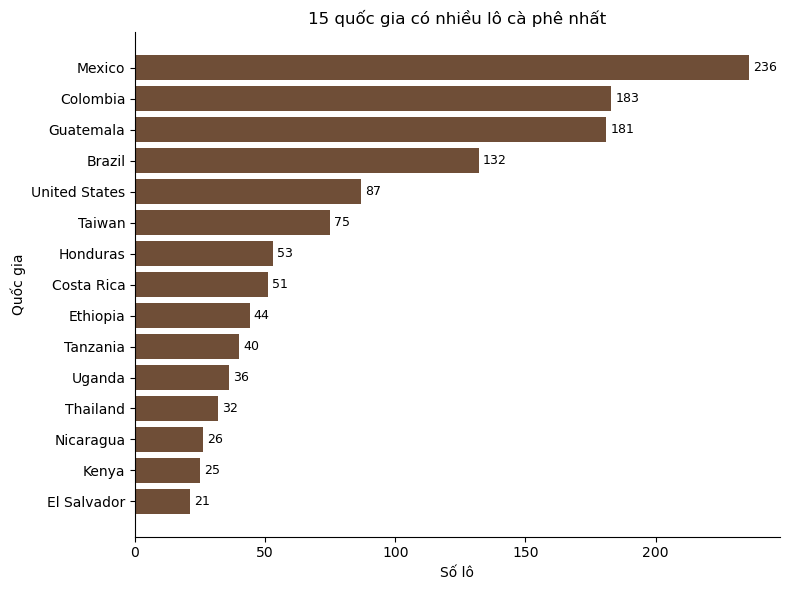

In [23]:
top15 = lots_per_country.head(15).sort_values()      # sắp tăng để cột dài nhất nằm trên cùng

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(top15.index, top15.values, color="#6F4E37")
ax.bar_label(bars, padding=3, fontsize=9)
ax.set_title("15 quốc gia có nhiều lô cà phê nhất")
ax.set_xlabel("Số lô")
ax.set_ylabel("Quốc gia")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

#### (e) Hai file By_Country / By_Continent có phải nguồn dữ liệu độc lập không?

Giả thuyết: 2 file này là **bảng tổng hợp** tính từ file chính (`Rec_Cnt` = số lô, các cột `AVG_*` = trung bình). Kiểm tra bằng cách tự groupby file chính rồi so sánh.

In [24]:
for name, table in [("df_country", df_country), ("df_continent", df_continent)]:
    print(f"=== {name}: {table.shape} ===")
    print(list(table.columns))
    display(table.head())

=== df_country: (34, 15) ===
['Country.of.Origin', 'AVG_Aroma', 'AVG_Flavor', 'AVG_Aftertaste', 'AVG_Acidity', 'AVG_Body', 'AVG_Balance', 'AVG_Uniformity', 'AVG_Clean.Cup', 'AVG_Sweetness', 'AVG_Moisture', 'AVG_Quakers', 'AVG_Category.One.Defects', 'AVG_Category.Two.Defects', 'Rec_Cnt']


,Country.of.Origin,AVG_Aroma,AVG_Flavor,AVG_Aftertaste,AVG_Acidity,AVG_Body,AVG_Balance,AVG_Uniformity,AVG_Clean.Cup,AVG_Sweetness,AVG_Moisture,AVG_Quakers,AVG_Category.One.Defects,AVG_Category.Two.Defects,Rec_Cnt
0,Brazil,7.553106,7.573561,7.440530,7.511439,7.544545,7.531515,9.884924,9.853485,9.949394,0.082348,0.446970,0.128788,3.598485,132
1,Burundi,7.415000,7.460000,7.250000,7.415000,7.290000,7.415000,10.000000,10.000000,10.000000,0.060000,0.000000,0.000000,2.500000,2
2,China,7.641250,7.625625,7.484375,7.578125,7.573750,7.548125,9.958125,9.958125,9.916250,0.094375,0.500000,0.000000,4.000000,16
3,Colombia,7.653060,7.597104,7.524699,7.560000,7.609508,7.708415,9.934426,9.945355,9.952678,0.062022,0.207650,0.377049,1.939891,183
4,Costa Rica,7.671373,7.537255,7.534510,7.573922,7.537451,7.637255,9.856275,9.869216,9.908431,0.083333,0.117647,0.352941,2.823529,51


=== df_continent: (5, 15) ===
['Country.of.Origin', 'AVG_Aroma', 'AVG_Flavor', 'AVG_Aftertaste', 'AVG_Acidity', 'AVG_Body', 'AVG_Balance', 'AVG_Uniformity', 'AVG_Clean.Cup', 'AVG_Sweetness', 'AVG_Moisture', 'AVG_Quakers', 'AVG_Category.One.Defects', 'AVG_Category.Two.Defects', 'Rec_Cnt']


,Country.of.Origin,AVG_Aroma,AVG_Flavor,AVG_Aftertaste,AVG_Acidity,AVG_Body,AVG_Balance,AVG_Uniformity,AVG_Clean.Cup,AVG_Sweetness,AVG_Moisture,AVG_Quakers,AVG_Category.One.Defects,AVG_Category.Two.Defects,Rec_Cnt
0,Africa,7.759444,7.709444,7.623889,7.739074,7.680741,7.689938,9.954568,9.979321,9.813148,0.100926,0.166667,0.179012,3.734568,162
1,Asia,7.539121,7.499286,7.409231,7.478407,7.509066,7.473187,9.908187,9.970604,9.761813,0.079066,0.115385,0.752747,1.538462,182
2,North America,7.504346,7.445714,7.300767,7.496677,7.450977,7.432496,9.752632,9.734226,9.852992,0.096857,0.129323,0.566917,4.518797,665
3,Oceania,8.330000,8.420000,7.830000,8.330000,8.000000,8.250000,9.330000,9.330000,10.000000,0.120000,0.000000,0.000000,1.000000,1
4,South America,7.613415,7.589878,7.491585,7.545915,7.574756,7.629177,9.902866,9.894268,9.937470,0.070030,0.298780,0.301829,2.646341,328


In [25]:
# Groupby rồi so sánh
# 1. Dò tên cột trong df_country
key_col   = df_country.select_dtypes(exclude="number").columns[0]   # cột tên quốc gia
count_col = [c for c in df_country.columns if "cnt" in c.lower()][0] # cột Rec_Cnt
avg_cols  = [c for c in df_country.columns if c.upper().startswith("AVG")]

def match_raw_col(avg_col):
    """'AVG_Clean_Cup' -> 'Clean.Cup' (cột tương ứng trong df), không thấy thì trả None."""
    base = avg_col[4:].lower().replace("_", "").replace(".", "")
    for c in df.columns:
        if c.lower().replace(".", "").replace("_", "") == base:
            return c
    return None

avg_map = {a: match_raw_col(a) for a in avg_cols}
print("Cột khoá:", key_col, "| Cột đếm:", count_col)
print("Ánh xạ AVG -> cột gốc:", avg_map)

# 2. Tự tổng hợp từ file chính
raw_cols = [c for c in avg_map.values() if c is not None]
mine = (df.groupby("Country.of.Origin")
          .agg(n_lots=("REC_ID", "size"), **{f"mine_{c}": (c, "mean") for c in raw_cols})
          .reset_index())

# 3. Ghép với df_country để so sánh
compare = df_country.merge(mine, left_on=key_col, right_on="Country.of.Origin",
                           how="outer", indicator=True)
print(compare["_merge"].value_counts())
compare[[key_col, count_col, "n_lots"] + avg_cols[:2] + [f"mine_{c}" for c in raw_cols[:2]]].head(10)

Cột khoá: Country.of.Origin | Cột đếm: Rec_Cnt
Ánh xạ AVG -> cột gốc: {'AVG_Aroma': 'Aroma', 'AVG_Flavor': 'Flavor', 'AVG_Aftertaste': 'Aftertaste', 'AVG_Acidity': 'Acidity', 'AVG_Body': 'Body', 'AVG_Balance': 'Balance', 'AVG_Uniformity': 'Uniformity', 'AVG_Clean.Cup': 'Clean.Cup', 'AVG_Sweetness': 'Sweetness', 'AVG_Moisture': 'Moisture', 'AVG_Quakers': 'Quakers', 'AVG_Category.One.Defects': 'Category.One.Defects', 'AVG_Category.Two.Defects': 'Category.Two.Defects'}
_merge
both          34
left_only      0
right_only     0
Name: count, dtype: int64


,Country.of.Origin,Rec_Cnt,n_lots,AVG_Aroma,AVG_Flavor,mine_Aroma,mine_Flavor
0,Brazil,132,132,7.553106,7.573561,7.553106,7.573561
1,Burundi,2,2,7.415000,7.460000,7.415000,7.460000
2,China,16,16,7.641250,7.625625,7.641250,7.625625
3,Colombia,183,183,7.653060,7.597104,7.653060,7.597104
4,Costa Rica,51,51,7.671373,7.537255,7.671373,7.537255
5,Cote dIvoire,1,1,7.420000,7.250000,7.420000,7.250000
6,Ecuador,3,3,7.583333,7.640000,7.583333,7.640000
7,El Salvador,21,21,7.674762,7.654286,7.674762,7.654286
8,Ethiopia,44,44,7.896364,8.009091,7.896364,8.009091
9,Guatemala,181,181,7.544862,7.489006,7.544862,7.489006


In [26]:
# TEST
both = compare[compare["_merge"] == "both"]

# a) mọi quốc gia đều khớp tên
assert (compare["_merge"] == "both").all(), \
    f"Có quốc gia không khớp tên:\n{compare.loc[compare['_merge'] != 'both', [key_col, 'Country.of.Origin', '_merge']]}"

# b) số lô khớp Rec_Cnt
assert (both[count_col] == both["n_lots"]).all(), \
    f"Số lô lệch ở:\n{both.loc[both[count_col] != both['n_lots'], [key_col, count_col, 'n_lots']]}"

# c) trung bình khớp (làm tròn 2 chữ số vì file tổng hợp có thể đã làm tròn)
for avg_col, raw_col in avg_map.items():
    if raw_col is None:
        continue
    ok = np.allclose(both[avg_col], both[f"mine_{raw_col}"].round(2), atol=0.01)
    assert ok, f"{avg_col} không khớp với trung bình của {raw_col}"

print(f"df_country được tổng hợp từ df: khớp {len(both)} quốc gia, {len(avg_map)} cột AVG")

df_country được tổng hợp từ df: khớp 34 quốc gia, 13 cột AVG


**Kết luận — (e):**
- Cả 2 file `By_Country` (34 dòng) và `By_Continent` (5 dòng) đều là bảng tổng hợp tính ra từ file chính: `Rec_Cnt` khớp với số lô đếm được và 13 cột `AVG_*` khớp với trung bình tự tính cho cả 34 quốc gia và 5 châu lục. Sai lệch lớn nhất chỉ khoảng 10⁻¹⁵, là sai số dấu phẩy động, nên các giá trị trùng khớp hoàn toàn và file tổng hợp không hề làm tròn. Không có quốc gia hay châu lục nào lệch tên hoặc lệch số lô. *(Lưu ý: cột khoá của `By_Continent` bị đặt tên là `Country.of.Origin` dù chứa tên châu lục.)*
- Vì vậy 2 file này không chứa thông tin mới ngoài những gì một lệnh `groupby` trên file chính đã cho; chúng không phải nguồn dữ liệu độc lập.
- Về hình thức, nối với một bảng khác trong cùng bộ dữ liệu vẫn được tính là D1, nhưng phép nối như vậy không giúp trả lời được câu hỏi nào mới. Nhóm chọn nối với dữ liệu sản lượng FAOSTAT (câu Q5) vì nguồn này thực sự bổ sung thông tin bên ngoài (quy mô sản xuất của từng quốc gia) mà bộ CQI không có. File `By_Country` chỉ được giữ làm phương án dự phòng cho D1 và để đối chiếu.

#### (f) Hạn chế và thiên lệch đã biết

| Hạn chế | Bằng chứng từ dữ liệu | Ảnh hưởng tới phân tích |
|---|---|---|
| Thiên lệch chọn mẫu: chỉ có những lô được **gửi tới CQI để chấm**, không đại diện cho mọi lô cà phê trên thế giới | (lý luận, không có số) | Kết luận chỉ áp dụng cho các lô được gửi chấm |
| Mất cân bằng loài | Arabica 1.311 lô (97,91%) / Robusta 28 lô (2,09%) | Có thể chỉ phân tích Arabica |
| Độ phủ quốc gia không đều | 14/34 quốc gia có < 10 lô (tổng 45 lô, 3,4%), 6 nước chỉ có 1 lô; top 3 quốc gia (Mexico, Colombia, Guatemala) chiếm 44,8% | So sánh giữa các nước nhỏ không ổn định |
| Dữ liệu cũ, phân bố năm không đều | Năm thu hoạch 2009–2018, 60 lô (4,5%) thiếu năm; năm ít nhất (2018) chỉ có 1 lô, trong khi 2012 có 354 lô | Không suy ra xu hướng hiện tại |
| Thiếu một số biến quan trọng | Không có tổng điểm, điểm cupper, độ cao, giá | Nhóm phải tự tạo `total_9` |
| Dữ liệu scrape rồi chỉnh sửa, có thể có lỗi nhập liệu | Chi tiết ở 3.2 (giá trị 0, outlier) | Cần làm sạch trước khi phân tích |

**Collection method:**

- **Cách thu thập:** dữ liệu không do nhóm tự thu thập mà được scrape bằng script Python từ cơ sở dữ liệu công khai của CQI (01/2018). Bộ dữ liệu sau đó qua tay nhiều người trên Kaggle (Volpatto 2019, Boyar 2023) trước khi RealDealAdamP chỉnh sửa và công bố bản nhóm dùng (03/2024).
- **Quần thể:** 1.339 lô cà phê đã được Q Grader của CQI chấm điểm, đến từ 34 quốc gia thuộc 5 châu lục. Gần như toàn bộ là Arabica (97,91%); châu Mỹ chiếm hơn 74% số lô (Bắc Mỹ 49,66%, Nam Mỹ 24,50%).
- **Giai đoạn:** năm thu hoạch 2009–2018, tập trung ở 2012–2016 (86,3% số lô có năm); theo `Expiration`, các lô được chấm khoảng 04/2010–01/2018, khớp với thời điểm scrape. Hai file `By_Country`/`By_Continent` chỉ là bảng tổng hợp từ file chính nên không mở rộng thêm phạm vi dữ liệu.
- **Hạn chế:** mẫu chỉ gồm các lô được gửi tới CQI (thiên lệch chọn mẫu), mất cân bằng loài, độ phủ quốc gia rất lệch (14 nước có < 10 lô, top 3 nước chiếm 44,8%), dữ liệu đã cũ và thiếu tổng điểm, độ cao, giá. Vì vậy kết luận của nhóm chỉ áp dụng cho **các lô Arabica được chấm bởi CQI trong khoảng 2010–2018**, và các so sánh liên quan tới nước hoặc năm ít lô cần được gộp/loại và nêu rõ.

### 3.1.5. Motivation

Nhóm chọn bộ *Coffee Quality with Locations of Origin* vì 4 lý do:

**1. Chủ đề có ý nghĩa thực tế.** Điểm cupping của CQI được dùng làm thước đo chung khi mua bán cà phê nhân: lô đạt từ 80 điểm trở lên được xếp là cà phê đặc sản (specialty) và thường bán được giá cao hơn. Vì vậy câu hỏi *"điều gì gắn với một lô cà phê chất lượng cao?"* có người dùng cụ thể:
- **Nông hộ, hợp tác xã:** nên chọn giống, cách sơ chế nào, và cần kiểm soát độ ẩm, lỗi hạt ra sao trước khi gửi chấm.
- **Nhà nhập khẩu, nhà rang xay:** nên tìm nguồn hàng ở quốc gia, châu lục nào; quốc gia sản xuất nhiều có đồng nghĩa với chất lượng cao không.
- **Barista, người tiêu dùng:** điểm số ghi trên bao bì thực sự phản ánh những thuộc tính nào của tách cà phê.

**2. Dữ liệu phù hợp với yêu cầu đồ án.**
- *Dữ liệu thật:* 1.339 lô được Q Grader chấm, scrape từ cơ sở dữ liệu công khai của CQI (3.1.4a), không phải dữ liệu mô phỏng.
- *Đủ loại biến:* 13 biến số (9 thuộc tính cảm quan, độ ẩm, quakers, 2 loại lỗi hạt), các biến phân loại (loài, châu lục, 34 quốc gia, giống, màu hạt, cách sơ chế) và 2 biến thời gian (`Harvest.Year` 2009–2018, `Expiration`).
- *Đủ chất liệu cho các tiêu chí chiều sâu:* tự tạo biến `total_9` từ 9 thuộc tính cảm quan (D3); xu hướng theo năm (D2); kiểm tra một quan hệ có còn đúng trong từng quốc gia hoặc từng cách sơ chế không (D4); và có khoá quốc gia–năm để nối với dữ liệu sản lượng FAOSTAT (D1), nguồn bổ sung thông tin mà 2 file `By_Country`/`By_Continent` không có (3.1.4e).
- *Có bài toán ML tự nhiên:* dự đoán chất lượng của lô từ xuất xứ, cách sơ chế và các đặc tính vật lý của hạt.
- *Kích thước vừa phải:* 1.339 × 22, đủ để thống kê có ý nghĩa ở các nhóm lớn mà vẫn chạy nhanh. Các hạn chế (mất cân bằng loài, quốc gia ít lô, dữ liệu dừng ở 2018) đã được nhóm đo và ghi lại ở 3.1.4f để xử lý chủ động.

**3. Chưa bị khai thác quá nhiều.** Khác với Iris hay Titanic, bộ dữ liệu này ít được dùng làm ví dụ mẫu. TODO (Hiếu, theo `docs/related_work.md`): ghi số notebook công khai trên Kaggle và các notebook đó thường làm gì, để chỉ ra câu hỏi của nhóm khác họ ở đâu.

**4. Liên hệ với câu hỏi của nhóm.**
- **Q2 (ML):** 
- **Q4:** 
- **Q5:** 

### 3.1.6. Các file dữ liệu và cách nhóm sử dụng

In [27]:
# Tóm tắt 3 file
row_meaning = {
    MAIN_FILE.name:      "Một lô cà phê được CQI chấm điểm",
    COUNTRY_FILE.name:   "Một quốc gia (trung bình các chỉ số + số lô)",
    CONTINENT_FILE.name: "Một châu lục (trung bình các chỉ số + số lô)",
}
tables = {MAIN_FILE.name: df, COUNTRY_FILE.name: df_country, CONTINENT_FILE.name: df_continent}

files_summary = pd.DataFrame({
    "File":          list(tables.keys()),
    "Số dòng":       [t.shape[0] for t in tables.values()],
    "Số cột":        [t.shape[1] for t in tables.values()],
    "Một dòng là gì": [row_meaning[name] for name in tables],
})
files_summary

,File,Số dòng,Số cột,Một dòng là gì
0,Coffee_Qlty.csv,1339,22,Một lô cà phê được CQI chấm điểm
1,Coffee_Qlty_By_Country.csv,34,15,Một quốc gia (trung bình các chỉ số + số lô)
2,Coffee_Qlty_By_Continent.csv,5,15,Một châu lục (trung bình các chỉ số + số lô)


| File | Kích thước | Nội dung | Dùng cho |
|---|---|---|---|
| `Coffee_Qlty.csv` | 1.339 dòng × 22 cột | Mỗi dòng là một lô cà phê được CQI chấm điểm | File chính: exploration (3.2), Q1–Q6, mô hình ML |
| `Coffee_Qlty_By_Country.csv` | 34 dòng × 15 cột | Trung bình 13 chỉ số theo quốc gia (`AVG_*`) và số lô (`Rec_Cnt`) | Chỉ dùng để đối chiếu, phương án dự phòng cho D1 (đã kiểm chứng ở 3.1.4e) |
| `Coffee_Qlty_By_Continent.csv` | 5 dòng × 15 cột | Trung bình 13 chỉ số theo châu lục và số lô; cột khoá bị đặt tên `Country.of.Origin` dù chứa tên châu lục | Chỉ dùng để đối chiếu |


---
## 3.2. Data exploration


### 3.2.1. Overview
*(Đức Thịnh — `feat/eda-numeric`)*

**Mục tiêu:** xác định rõ cấu trúc bảng `Coffee_Qlty.csv` (1.339 dòng × 22 cột), ý nghĩa thực thể của một dòng, từ điển dữ liệu, kiểm tra khoá định danh, dòng rỗng, dòng trùng và kiểm toán ép kiểu dữ liệu trước khi đi sâu vào từng nhóm biến.

- **Thực thể một dòng:** Mỗi dòng đại diện cho **một bản ghi đánh giá chất lượng một lô cà phê nhân xanh (coffee lot evaluation)** do Q Grader của CQI thực hiện.
- **Khoá định danh:** Cột `REC_ID` chạy từ `0` đến `1338` (`1.339` giá trị duy nhất, không khuyết). Vì `REC_ID` chỉ là khoá kỹ thuật định danh bản ghi và không mang thông tin thuộc tính của lô cà phê, cột này được giữ ở bước EDA để truy vết bản ghi đặc biệt (như `REC_ID=1310`, `721`, `742`, `1197`) nhưng **sẽ bị loại khỏi tập đặc trưng phân tích thống kê và mô hình ML**.
- **Nguyên tắc bảo toàn trong mục 3.2:** Không ghi đè hay xoá dòng trực tiếp trên `df` gốc để các mục `3.2.3 Categorical` và `3.2.4 Missing data` cùng quan sát nguyên trạng 1.339 bản ghi.

#### a. Hình dạng bảng, mẫu dữ liệu thực tế và kiểm tra khoá `REC_ID`

In [28]:
# Kiểm tra kích thước, kiểu dữ liệu tổng quát và tính duy nhất của khoá REC_ID
overview_stats = pd.DataFrame([
    {"Chỉ tiêu": "Số dòng (bản ghi lô cà phê)", "Giá trị": f"{df.shape[0]:,}"},
    {"Chỉ tiêu": "Số cột gốc", "Giá trị": f"{df.shape[1]}"},
    {"Chỉ tiêu": "Số giá trị REC_ID duy nhất", "Giá trị": f"{df['REC_ID'].nunique():,}"},
    {"Chỉ tiêu": "REC_ID là khoá duy nhất (is_unique)", "Giá trị": str(bool(df["REC_ID"].is_unique))},
    {"Chỉ tiêu": "Số dòng rỗng hoàn toàn (all-NA)", "Giá trị": f"{int(df.isna().all(axis=1).sum())}"},
])
display(overview_stats)
print("5 dòng đầu tiên của dữ liệu (df.head(5)):")
display(df.head(5))

,Chỉ tiêu,Giá trị
0,Số dòng (bản ghi lô cà phê),"1,339"
1,Số cột gốc,22
2,Số giá trị REC_ID duy nhất,"1,339"
3,REC_ID là khoá duy nhất (is_unique),True
4,Số dòng rỗng hoàn toàn (all-NA),0


5 dòng đầu tiên của dữ liệu (df.head(5)):


,REC_ID,Species,Continent.of.Origin,Country.of.Origin,Harvest.Year,Expiration,Variety,Color,Processing.Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Moisture,Quakers,Category.One.Defects,Category.Two.Defects
0,0,Arabica,Africa,Ethiopia,2014.0,04/03/16,NaN,Green,Washed / Wet,8.67,8.83,8.67,8.75,8.50,8.42,10.0,10.0,10.0,0.12,0,0,0
1,1,Arabica,Africa,Ethiopia,2014.0,04/03/16,Other,Green,Washed / Wet,8.75,8.67,8.50,8.58,8.42,8.42,10.0,10.0,10.0,0.12,0,0,1
2,2,Arabica,North America,Guatemala,NaN,05/31/11,Bourbon,NaN,NaN,8.42,8.50,8.42,8.42,8.33,8.42,10.0,10.0,10.0,0.00,0,0,0
3,3,Arabica,Africa,Ethiopia,2014.0,03/25/16,NaN,Green,Natural / Dry,8.17,8.58,8.42,8.42,8.50,8.25,10.0,10.0,10.0,0.11,0,0,2
4,4,Arabica,Africa,Ethiopia,2014.0,04/03/16,Other,Green,Washed / Wet,8.25,8.50,8.25,8.50,8.42,8.33,10.0,10.0,10.0,0.12,0,0,2


#### b. Từ điển dữ liệu (Data Dictionary) và kiểm toán kiểu dữ liệu

Bảng dưới đây mô tả đầy đủ 22 cột trong `Coffee_Qlty.csv`: nhóm vai trò, ý nghĩa, đơn vị/miền giá trị kỳ vọng, kiểu dữ liệu khi đọc từ CSV, kiểu dữ liệu mục tiêu, số giá trị khác nhau (`n_unique`), số ô thiếu (`n_missing`) và quyết định xử lý cột.

In [29]:
COLUMN_SPECS = [
    ("REC_ID", "Định danh", "Mã bản ghi lô cà phê trong CQI", "Số nguyên [0..1338]", "int64", "Giữ làm khoá truy vết ở EDA; bỏ khi phân tích/ML"),
    ("Species", "Xuất xứ", "Loài cà phê", "Arabica / Robusta", "category", "Giữ; kiểm tra mất cân bằng loài (97,91% Arabica)"),
    ("Continent.of.Origin", "Xuất xứ", "Châu lục xuất xứ của lô cà phê", "Tên châu lục (5 nhóm)", "category", "Giữ; chuẩn hoá nhãn"),
    ("Country.of.Origin", "Xuất xứ", "Quốc gia xuất xứ của lô cà phê", "Tên quốc gia (34 nước)", "category", "Giữ; chuẩn hoá nhãn và nối FAOSTAT ở Q5"),
    ("Harvest.Year", "Thông tin lô", "Năm thu hoạch lô cà phê", "Năm (YYYY, 2009–2018)", "Int64", "Ép sang Int64 vì float64 do có 60 ô NaN"),
    ("Expiration", "Thông tin lô", "Ngày hết hạn chứng nhận CQI (1 năm sau chấm)", "Ngày (MM/DD/YY)", "datetime64[ns]", "Ép sang datetime để đối chiếu mốc thời gian"),
    ("Variety", "Thông tin lô", "Giống cây cà phê", "Tên giống (29 nhãn)", "category", "Giữ; chuẩn hoá và tạo bản gộp nhóm hiếm (<20 lô)"),
    ("Color", "Thông tin lô", "Màu sắc hạt cà phê nhân xanh trước khi rang", "Green, Bluish-Green, Blue-Green, None", "category", "Giữ; lưu ý nhãn chuỗi 'None' (52 lô) khác với NaN"),
    ("Processing.Method", "Thông tin lô", "Phương pháp sơ chế sau thu hoạch", "Washed / Wet, Natural / Dry, ...", "category", "Giữ; biến trọng tâm cho Q1"),
    ("Aroma", "Cảm quan", "Điểm hương thơm (khô và sau khi pha nước)", "Điểm SCA (thang 0–10)", "float64", "Giữ; thành phần tính total_9"),
    ("Flavor", "Cảm quan", "Điểm hương vị chủ đạo khi nếm", "Điểm SCA (thang 0–10)", "float64", "Giữ; thành phần tính total_9"),
    ("Aftertaste", "Cảm quan", "Điểm hậu vị lưu lại sau khi nuốt/nhổ", "Điểm SCA (thang 0–10)", "float64", "Giữ; thành phần tính total_9"),
    ("Acidity", "Cảm quan", "Điểm độ chua thanh/tươi sáng", "Điểm SCA (thang 0–10)", "float64", "Giữ; thành phần tính total_9"),
    ("Body", "Cảm quan", "Điểm độ sánh đậm/cảm giác miệng", "Điểm SCA (thang 0–10)", "float64", "Giữ; thành phần tính total_9"),
    ("Balance", "Cảm quan", "Điểm độ cân bằng giữa Flavor, Aftertaste, Acidity, Body", "Điểm SCA (thang 0–10)", "float64", "Giữ; thành phần tính total_9"),
    ("Uniformity", "Cảm quan", "Độ đồng nhất hương vị giữa 5 tách mẫu (2 điểm/tách)", "Điểm SCA (0–10, bước 2)", "float64", "Giữ; lưu ý hiệu ứng trần điểm (86,1% đạt 10)"),
    ("Clean.Cup", "Cảm quan", "Độ sạch vị, không có mùi vị lạ trên 5 tách mẫu", "Điểm SCA (0–10, bước 2)", "float64", "Giữ; lưu ý hiệu ứng trần điểm (91,1% đạt 10)"),
    ("Sweetness", "Cảm quan", "Độ ngọt tự nhiên cảm nhận trên 5 tách mẫu", "Điểm SCA (0–10, bước 2)", "float64", "Giữ; lưu ý hiệu ứng trần điểm (91,0% đạt 10)"),
    ("Moisture", "Vật lý / lỗi hạt", "Độ ẩm của hạt cà phê nhân xanh (tỷ lệ phần thập phân)", "Tỷ lệ [0,00–0,28] (10% = 0,10)", "float64", "Giữ; kiểm tra 264 lô có Moisture = 0,00"),
    ("Quakers", "Vật lý / lỗi hạt", "Số hạt chưa chín (quakers) phát hiện sau khi rang mẫu", "Số hạt nguyên >= 0", "int64", "Giữ; biến phân tích Q3 và đặc trưng ML Q2"),
    ("Category.One.Defects", "Vật lý / lỗi hạt", "Số lỗi sơ cấp (nặng: hạt đen, chua toàn phần...) trên 350g nhân", "Số lỗi nguyên >= 0", "int64", "Giữ; biến phân tích Q3 và đặc trưng ML Q2"),
    ("Category.Two.Defects", "Vật lý / lỗi hạt", "Số lỗi thứ cấp (nhẹ: hạt vỡ, vỏ trấu, sâu đục...) trên 350g nhân", "Số lỗi nguyên >= 0", "int64", "Giữ; biến phân tích Q3 và đặc trưng ML Q2"),
]

data_dictionary = pd.DataFrame(
    COLUMN_SPECS,
    columns=["column", "group", "meaning", "unit_or_range", "target_dtype", "decision"],
)
data_dictionary["current_dtype"] = [str(df[c].dtype) for c in data_dictionary["column"]]
data_dictionary["n_unique"] = [int(df[c].nunique(dropna=True)) for c in data_dictionary["column"]]
data_dictionary["n_missing"] = [int(df[c].isna().sum()) for c in data_dictionary["column"]]
data_dictionary["pct_missing"] = [round(df[c].isna().mean() * 100, 2) for c in data_dictionary["column"]]

cols_order = [
    "column", "group", "meaning", "unit_or_range",
    "current_dtype", "target_dtype", "n_unique", "n_missing", "pct_missing", "decision"
]
data_dictionary = data_dictionary[cols_order]
display(data_dictionary)

,column,group,meaning,unit_or_range,current_dtype,target_dtype,n_unique,n_missing,pct_missing,decision
0,REC_ID,Định danh,Mã bản ghi lô cà phê trong CQI,Số nguyên [0..1338],int64,int64,1339,0,0.00,Giữ làm khoá truy vết ở EDA; bỏ khi phân tích/ML
1,Species,Xuất xứ,Loài cà phê,Arabica / Robusta,object,category,2,0,0.00,"Giữ; kiểm tra mất cân bằng loài (97,91% Arabica)"
2,Continent.of.Origin,Xuất xứ,Châu lục xuất xứ của lô cà phê,Tên châu lục (5 nhóm),object,category,5,1,0.07,Giữ; chuẩn hoá nhãn
3,Country.of.Origin,Xuất xứ,Quốc gia xuất xứ của lô cà phê,Tên quốc gia (34 nước),object,category,34,1,0.07,Giữ; chuẩn hoá nhãn và nối FAOSTAT ở Q5
4,Harvest.Year,Thông tin lô,Năm thu hoạch lô cà phê,"Năm (YYYY, 2009–2018)",float64,Int64,10,60,4.48,Ép sang Int64 vì float64 do có 60 ô NaN
5,Expiration,Thông tin lô,Ngày hết hạn chứng nhận CQI (1 năm sau chấm),Ngày (MM/DD/YY),object,datetime64[ns],565,0,0.00,Ép sang datetime để đối chiếu mốc thời gian
6,Variety,Thông tin lô,Giống cây cà phê,Tên giống (29 nhãn),object,category,29,226,16.88,Giữ; chuẩn hoá và tạo bản gộp nhóm hiếm (<20 lô)
7,Color,Thông tin lô,Màu sắc hạt cà phê nhân xanh trước khi rang,"Green, Bluish-Green, Blue-Green, None",object,category,4,218,16.28,Giữ; lưu ý nhãn chuỗi 'None' (52 lô) khác với NaN
8,Processing.Method,Thông tin lô,Phương pháp sơ chế sau thu hoạch,"Washed / Wet, Natural / Dry, ...",object,category,5,170,12.70,Giữ; biến trọng tâm cho Q1
9,Aroma,Cảm quan,Điểm hương thơm (khô và sau khi pha nước),Điểm SCA (thang 0–10),float64,float64,33,0,0.00,Giữ; thành phần tính total_9


#### c. Làm sạch cấu trúc: kiểm tra dòng trùng, cột hằng số và ép kiểu (`errors='coerce'`)

Thực hiện kiểm tra 3 hạng mục cấu trúc:
1. **Cột hằng số (`nunique == 1`) hoặc cột trùng nội dung:** Kiểm tra xem có cột nào vô nghĩa cần loại bỏ ngay không.
2. **Dòng trùng lặp:** Kiểm tra trùng toàn bộ 22 cột (`df.duplicated()`) và trùng trên 21 cột thuộc tính ngoài khoá `REC_ID`.
3. **Ép kiểu dữ liệu (`pd.to_numeric`, `pd.to_datetime` với `errors='coerce'`):** Đếm số `NaN` mới phát sinh sau khi ép kiểu để phát hiện các giá trị bẩn không đúng định dạng.

In [30]:
# 1. Kiểm tra cột hằng số (chỉ có 1 giá trị)
constant_cols = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]

# 2. Kiểm tra dòng trùng toàn bộ và dòng trùng trên 21 cột ngoài REC_ID
n_full_dup = int(df.duplicated().sum())
non_id_cols = [c for c in df.columns if c != "REC_ID"]
n_attr_dup_pairs = int(df.duplicated(subset=non_id_cols, keep="first").sum())
attr_dup_rows = df[df.duplicated(subset=non_id_cols, keep=False)].sort_values("REC_ID")

print(f"Số cột chỉ có <= 1 giá trị duy nhất : {len(constant_cols)} ({constant_cols})")
print(f"Số dòng trùng tuyệt đối cả 22 cột   : {n_full_dup}")
print(f"Số cặp dòng trùng toàn bộ 21 cột ngoài REC_ID: {n_attr_dup_pairs} cặp ({len(attr_dup_rows)} dòng)")
print("\nChi tiết 2 bản ghi trùng toàn bộ thuộc tính ngoài REC_ID:")
display(attr_dup_rows)

# 3. Kiểm toán ép kiểu (coercion audit) cho cột thời gian và các cột số
coercion_rows = []
# Kiểm tra Harvest.Year
hy_coerced = pd.to_numeric(df["Harvest.Year"], errors="coerce")
coercion_rows.append({
    "column": "Harvest.Year",
    "original_dtype": str(df["Harvest.Year"].dtype),
    "target_conversion": "pd.to_numeric(..., errors='coerce') -> Int64",
    "na_before": int(df["Harvest.Year"].isna().sum()),
    "na_after": int(hy_coerced.isna().sum()),
    "new_na_from_dirty_values": int(hy_coerced.isna().sum() - df["Harvest.Year"].isna().sum()),
})

# Kiểm tra Expiration
exp_coerced = pd.to_datetime(df["Expiration"], format="%m/%d/%y", errors="coerce")
coercion_rows.append({
    "column": "Expiration",
    "original_dtype": str(df["Expiration"].dtype),
    "target_conversion": "pd.to_datetime(..., format='%m/%d/%y', errors='coerce')",
    "na_before": int(df["Expiration"].isna().sum()),
    "na_after": int(exp_coerced.isna().sum()),
    "new_na_from_dirty_values": int(exp_coerced.isna().sum() - df["Expiration"].isna().sum()),
})

# Kiểm tra 13 cột số (9 cảm quan + 4 vật lý)
for col in SCORE_COLS + ["Moisture", "Quakers", "Category.One.Defects", "Category.Two.Defects"]:
    num_coerced = pd.to_numeric(df[col], errors="coerce")
    coercion_rows.append({
        "column": col,
        "original_dtype": str(df[col].dtype),
        "target_conversion": "pd.to_numeric(..., errors='coerce')",
        "na_before": int(df[col].isna().sum()),
        "na_after": int(num_coerced.isna().sum()),
        "new_na_from_dirty_values": int(num_coerced.isna().sum() - df[col].isna().sum()),
    })

coercion_audit = pd.DataFrame(coercion_rows).set_index("column")
print("\nBảng kiểm toán ép kiểu (số NaN mới sinh = số chuỗi bẩn không đọc được):")
display(coercion_audit)

Số cột chỉ có <= 1 giá trị duy nhất : 0 ([])
Số dòng trùng tuyệt đối cả 22 cột   : 0
Số cặp dòng trùng toàn bộ 21 cột ngoài REC_ID: 1 cặp (2 dòng)

Chi tiết 2 bản ghi trùng toàn bộ thuộc tính ngoài REC_ID:


,REC_ID,Species,Continent.of.Origin,Country.of.Origin,Harvest.Year,Expiration,Variety,Color,Processing.Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Moisture,Quakers,Category.One.Defects,Category.Two.Defects
721,721,Arabica,Asia,Taiwan,2013.0,12/26/14,Typica,Green,Washed / Wet,7.5,7.5,7.5,7.5,7.5,7.5,10.0,10.0,10.0,0.11,0,0,0
742,742,Arabica,Asia,Taiwan,2013.0,12/26/14,Typica,Green,Washed / Wet,7.5,7.5,7.5,7.5,7.5,7.5,10.0,10.0,10.0,0.11,0,0,0



Bảng kiểm toán ép kiểu (số NaN mới sinh = số chuỗi bẩn không đọc được):


,original_dtype,target_conversion,na_before,na_after,new_na_from_dirty_values
column,,,,,
Harvest.Year,float64,"pd.to_numeric(..., errors='coerce') -> Int64",60,60,0
Expiration,object,"pd.to_datetime(..., format='%m/%d/%y', errors=...",0,0,0
Aroma,float64,"pd.to_numeric(..., errors='coerce')",0,0,0
Flavor,float64,"pd.to_numeric(..., errors='coerce')",0,0,0
Aftertaste,float64,"pd.to_numeric(..., errors='coerce')",0,0,0
Acidity,float64,"pd.to_numeric(..., errors='coerce')",0,0,0
Body,float64,"pd.to_numeric(..., errors='coerce')",0,0,0
Balance,float64,"pd.to_numeric(..., errors='coerce')",0,0,0
Uniformity,float64,"pd.to_numeric(..., errors='coerce')",0,0,0


In [31]:
# TEST — Kiểm tra tính toàn vẹn của mục 3.2.1 Overview
assert df.shape == (1339, 22), "df gốc phải giữ nguyên 1.339 dòng × 22 cột"
assert len(data_dictionary) == 22, "Từ điển dữ liệu phải mô tả đủ 22 cột"
assert set(data_dictionary["column"]) == set(df.columns), "Các cột trong từ điển phải khớp với df.columns"
assert len(constant_cols) == 0, "Không có cột hằng số nào trong dữ liệu"
assert n_full_dup == 0, "Không có dòng trùng tuyệt đối cả 22 cột"
assert set(attr_dup_rows["REC_ID"]) == {721, 742}, "Hai bản ghi trùng thuộc tính ngoài REC_ID phải là 721 và 742"
assert (coercion_audit["new_na_from_dirty_values"] == 0).all(), "Không phát sinh NaN mới khi ép kiểu"
print("Overview checks passed")

Overview checks passed


#### Nhận xét — Overview

- **Đơn vị quan sát và khoá chính:** Bảng dữ liệu chính `Coffee_Qlty.csv` có đúng **1.339 dòng × 22 cột**, không có dòng rỗng hoàn toàn (`0` dòng all-NA). Mỗi dòng là một bản ghi chấm điểm một lô cà phê, được định danh duy nhất bởi `REC_ID` (`0` đến `1338`). Cột `REC_ID` chỉ phục vụ truy vết bản ghi trong quá trình làm sạch, không đưa vào làm biến giải thích hay đặc trưng mô hình.
- **Kiểm toán ép kiểu (`errors='coerce'`):** Toàn bộ 13 cột số (`9` cột điểm cảm quan và `4` cột vật lý/lỗi hạt) đã ở đúng kiểu `float64`/`int64` mà không có giá trị chuỗi bẩn nào (`new_na_from_dirty_values = 0`). Hai cột thời gian cần chuẩn hoá kiểu khi phân tích gồm:
  - `Harvest.Year` đang có kiểu `float64` do chứa `60` ô thiếu (`NaN`); toàn bộ `1.279` giá trị hiện có đều là số nguyên năm từ `2009` đến `2018`, ép sang `Int64` sinh `0` `NaN` mới.
  - `Expiration` đang ở kiểu chuỗi `object` định dạng `MM/DD/YY`; khi ép bằng `pd.to_datetime(..., format="%m/%d/%y", errors="coerce")` tất cả `1.339/1.339` dòng đều hợp lệ (`0` `NaN` mới).
- **Phát hiện 2 dòng trùng toàn bộ thuộc tính ngoài `REC_ID` (`REC_ID = 721` và `REC_ID = 742`):**
  - Hai bản ghi này đều là lô `Arabica`, xuất xứ `Taiwan`, thu hoạch năm `2013`, hết hạn chứng nhận cùng ngày `12/26/14`, giống `Typica`, màu `Green`, sơ chế `Washed / Wet`, và trùng khít cả 9 điểm cảm quan (`Aroma=7.50, Flavor=7.50, Aftertaste=7.25, Acidity=7.33, Body=7.33, Balance=7.33, Uniformity=10.0, Clean.Cup=10.0, Sweetness=10.0`, `total_9 = 74.24`) lẫn 4 chỉ số vật lý (`Moisture=0.11`, `Quakers=0`, `Category.One.Defects=0`, `Category.Two.Defects=0`).
  - **Quyết định và lý do:** Trong thực tế CQI, một nhà sản xuất có thể gửi hai lô mẫu cùng giống, cùng đợt sơ chế và nhận điểm tương đương, hoặc đây là bản ghi bị nhập đúp thành hai mã `REC_ID`. Nhóm **chưa xoá ở bước EDA** để giữ nguyên mẫu `1.338` lô có điểm hợp lệ cho các thống kê mô tả chung, nhưng sẽ đưa cặp `721/742` vào diện kiểm tra độ nhạy và loại bỏ bản lặp trước khi chia train/test ở bài toán ML (Q2) nhằm tránh rò rỉ dữ liệu.

### 3.2.2. Numerical columns
*(Đức Thịnh — `feat/eda-numeric`)*

**Mục tiêu:** phân tích sâu 13 cột số gốc cùng biến tổng hợp `total_9` (tổng 9 thuộc tính cảm quan, thang `0–90`) phục vụ các câu hỏi nghiên cứu Q1–Q6:
1. Kiểm tra tính hợp lý thực tế của `min`/`max` và phát hiện các giá trị giữ chỗ (placeholder `0`, `999`, `-1`).
2. So sánh thống kê trung tâm (`mean` vs `median`), độ phân tán (`std`, `IQR`) và hình dạng phân phối (`skewness`, `kurtosis`) trước và sau khi loại bản ghi lỗi `REC_ID = 1310`.
3. Định lượng số lượng và tỷ lệ outlier theo 3 quy tắc (`1.5 IQR`, `3.0 IQR`, `|z-score| > 3`), kết hợp trực quan hoá bằng **Histogram** và **Boxplot**.
4. Phân biệt rõ giữa **lỗi nhập liệu / giá trị giữ chỗ** (như `REC_ID=1310` có cả 9 điểm bằng `0`, hoặc `264` lô có `Moisture = 0.00`) với **giá trị thật hiếm gặp** (các lô nhiều lỗi hạt hoặc điểm cảm quan thấp thật sự).

#### a. Phát hiện bản ghi lỗi điểm cảm quan (`REC_ID = 1310`) và đối chiếu thống kê trước/sau

Theo giao thức chấm điểm SCA/CQI, mỗi thuộc tính cảm quan được chấm trên thang `0–10`, nhưng các lô cà phê gửi đánh giá thực tế thường nằm trong vùng `5–10` điểm/thuộc tính. Trước khi đọc bảng thống kê, ta rà soát các giá trị bằng `0` trên 9 cột cảm quan (`SCORE_COLS`) và 4 cột vật lý.

In [32]:
PHYS_COLS = ["Moisture", "Quakers", "Category.One.Defects", "Category.Two.Defects"]
df_num_raw = add_total_score(df)
NUM_ANALYZE_COLS = [*SCORE_COLS, "total_9", *PHYS_COLS]

# Kiểm tra các dòng có bất kỳ cột cảm quan nào bằng 0
zero_sensory_mask = df_num_raw[SCORE_COLS].eq(0).any(axis=1)
print(f"Số lô có ít nhất 1 thuộc tính cảm quan bằng 0: {int(zero_sensory_mask.sum())} lô")
display(
    df_num_raw.loc[
        zero_sensory_mask,
        ["REC_ID", "Species", "Country.of.Origin", "Harvest.Year", *SCORE_COLS, "total_9", "Moisture", "Category.Two.Defects"]
    ]
)

Số lô có ít nhất 1 thuộc tính cảm quan bằng 0: 2 lô


,REC_ID,Species,Country.of.Origin,Harvest.Year,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,total_9,Moisture,Category.Two.Defects
1306,1306,Arabica,Mexico,2012.0,7.08,6.83,6.25,7.42,7.25,6.75,10.0,0.0,10.0,61.58,0.11,20
1310,1310,Arabica,Honduras,2017.0,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.00,0.12,2


Kết quả kiểm tra cho thấy có đúng **2 lô** xuất hiện điểm `0` ở các cột cảm quan nhưng bản chất hoàn toàn khác nhau:
- **Lô `REC_ID = 1310` (Honduras, 2017 — LỖI DỮ LIỆU):** Cả 9 thuộc tính trong `SCORE_COLS` đồng loạt bằng `0.00` (`total_9 = 0.00`), trong khi các thông tin vật lý vẫn bình thường (`Moisture = 0.12`, `Quakers = 0`, `Category.One.Defects = 0`, `Category.Two.Defects = 2`). Một mẫu cà phê có hạt nhân xanh bình thường không thể đạt `0` điểm tuyệt đối ở mọi tiêu chí khứu giác lẫn vị giác; đây là **bản ghi chưa có kết quả cupping được điền số `0` làm giá trị giữ chỗ (placeholder)**.
- **Lô `REC_ID = 1306` (Mexico, 2012 — GIÁ TRỊ THẬT HIẾM GẶP):** Chỉ riêng cột `Clean.Cup = 0.00` (tức cả 5 tách mẫu đều có lỗi vị lạ), trong khi 8 thuộc tính còn lại đều có điểm hợp lệ (`Aroma = 7.08`, `Flavor = 6.83`, `Uniformity = 10.0`, `Sweetness = 10.0`, `total_9 = 61.58`) và lô này có tới `20` lỗi `Category.Two.Defects`. Đây là một lô cà phê chất lượng kém thật sự, **không phải lỗi nhập liệu** nên phải được giữ lại.

Bảng dưới đây tổng hợp thống kê mô tả (`describe()`, `median`, `IQR`, `skew`, `kurt`, số giá trị `0`) trên `1.338` lô hợp lệ sau khi tách riêng `REC_ID = 1310`, kèm đối chiếu độ lệch của `total_9` trước và sau khi loại `REC_ID = 1310`:

In [33]:
df_num_valid = df_num_raw.loc[df_num_raw["REC_ID"].ne(1310)].copy()

# So sánh tác động của duy nhất 1 dòng REC_ID=1310 lên thống kê total_9
impact_1310 = pd.DataFrame([
    {
        "Mẫu": "Toàn bộ 1.339 lô (gồm REC_ID=1310)",
        "n": len(df_num_raw),
        "mean_total_9": df_num_raw["total_9"].mean(),
        "median_total_9": df_num_raw["total_9"].median(),
        "std_total_9": df_num_raw["total_9"].std(),
        "min_total_9": df_num_raw["total_9"].min(),
        "skew_total_9": df_num_raw["total_9"].skew(),
        "kurt_total_9": df_num_raw["total_9"].kurt(),
    },
    {
        "Mẫu": "1.338 lô hợp lệ (đã bỏ REC_ID=1310)",
        "n": len(df_num_valid),
        "mean_total_9": df_num_valid["total_9"].mean(),
        "median_total_9": df_num_valid["total_9"].median(),
        "std_total_9": df_num_valid["total_9"].std(),
        "min_total_9": df_num_valid["total_9"].min(),
        "skew_total_9": df_num_valid["total_9"].skew(),
        "kurt_total_9": df_num_valid["total_9"].kurt(),
    },
])
print("Tác động của bản ghi placeholder REC_ID=1310 lên biến tổng điểm total_9:")
display(impact_1310.round(3))

# Bảng thống kê chi tiết cho 14 biến số trên 1.338 lô hợp lệ
num_summary = df_num_valid[NUM_ANALYZE_COLS].describe().T
num_summary["median"] = df_num_valid[NUM_ANALYZE_COLS].median()
num_summary["IQR"] = num_summary["75%"] - num_summary["25%"]
num_summary["mean_minus_median"] = num_summary["mean"] - num_summary["median"]
num_summary["skew"] = df_num_valid[NUM_ANALYZE_COLS].skew()
num_summary["kurt"] = df_num_valid[NUM_ANALYZE_COLS].kurt()
num_summary["n_zeros"] = df_num_valid[NUM_ANALYZE_COLS].eq(0).sum()
num_summary["pct_zeros"] = (df_num_valid[NUM_ANALYZE_COLS].eq(0).mean() * 100).round(2)
num_summary["pct_equal_10"] = (df_num_valid[NUM_ANALYZE_COLS].eq(10.0).mean() * 100).round(2)

summary_cols = [
    "count", "mean", "median", "mean_minus_median", "std", "IQR",
    "min", "25%", "75%", "max", "skew", "kurt", "n_zeros", "pct_zeros", "pct_equal_10"
]
print("\nBảng thống kê mô tả 14 biến số trên mẫu 1.338 lô hợp lệ:")
display(num_summary[summary_cols].round(3))

Tác động của bản ghi placeholder REC_ID=1310 lên biến tổng điểm total_9:


,Mẫu,n,mean_total_9,median_total_9,std_total_9,min_total_9,skew_total_9,kurt_total_9
0,Toàn bộ 1.339 lô (gồm REC_ID=1310),1339,74.586,75.0,3.139,0.00,-10.954,240.911
1,1.338 lô hợp lệ (đã bỏ REC_ID=1310),1338,74.642,75.0,2.387,53.17,-2.152,11.169



Bảng thống kê mô tả 14 biến số trên mẫu 1.338 lô hợp lệ:


,count,mean,median,mean_minus_median,std,IQR,min,25%,75%,max,skew,kurt,n_zeros,pct_zeros,pct_equal_10
Aroma,1338.0,7.572,7.58,-0.008,0.316,0.330,5.08,7.420,7.75,8.75,-0.430,3.791,0,0.00,0.00
Flavor,1338.0,7.526,7.58,-0.054,0.341,0.420,6.08,7.330,7.75,8.83,-0.308,1.618,0,0.00,0.00
Aftertaste,1338.0,7.407,7.42,-0.013,0.350,0.330,6.17,7.250,7.58,8.67,-0.363,1.273,0,0.00,0.00
Acidity,1338.0,7.541,7.58,-0.039,0.319,0.420,5.25,7.330,7.75,8.75,-0.218,2.684,0,0.00,0.00
Body,1338.0,7.523,7.50,0.023,0.308,0.340,5.08,7.330,7.67,8.58,-0.962,7.719,0,0.00,0.00
Balance,1338.0,7.524,7.50,0.024,0.354,0.420,5.25,7.330,7.75,8.75,-0.253,2.174,0,0.00,0.00
Uniformity,1338.0,9.842,10.00,-0.158,0.485,0.000,6.00,10.000,10.00,10.00,-4.219,21.371,0,0.00,86.10
Clean.Cup,1338.0,9.842,10.00,-0.158,0.715,0.000,0.00,10.000,10.00,10.00,-7.158,66.163,1,0.07,91.11
Sweetness,1338.0,9.864,10.00,-0.136,0.554,0.000,1.33,10.000,10.00,10.00,-6.219,57.169,0,0.00,91.03
total_9,1338.0,74.642,75.00,-0.358,2.387,2.098,53.17,73.822,75.92,81.84,-2.152,11.169,0,0.00,0.00


#### b. Kiểm toán Outlier theo quy tắc IQR (`1.5 IQR`, `3.0 IQR`) và Z-score (`|z| > 3`)

Áp dụng cả quy tắc khoảng tứ phân vị (`IQR = Q3 - Q1`) và điểm chuẩn hoá (`z = (x - mean) / std`) trên `1.338` lô hợp lệ để định lượng số lượng outlier ở đuôi dưới và đuôi trên của từng biến.

In [34]:
outlier_rows = []
for col in NUM_ANALYZE_COLS:
    s = df_num_valid[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low_15, high_15 = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    low_30, high_30 = q1 - 3.0 * iqr, q3 + 3.0 * iqr
    z_scores = (s - s.mean()) / s.std()

    n_low_15 = int((s < low_15).sum())
    n_high_15 = int((s > high_15).sum())
    n_out_15 = n_low_15 + n_high_15
    n_out_30 = int(((s < low_30) | (s > high_30)).sum())
    n_z_gt3 = int((z_scores.abs() > 3).sum())

    outlier_rows.append({
        "column": col,
        "Q1": round(q1, 3),
        "Q3": round(q3, 3),
        "IQR": round(iqr, 3),
        "fence_low_1.5": round(low_15, 3),
        "fence_high_1.5": round(high_15, 3),
        "n_low_1.5IQR": n_low_15,
        "n_high_1.5IQR": n_high_15,
        "n_total_1.5IQR": n_out_15,
        "pct_1.5IQR": round(n_out_15 / len(s) * 100, 2),
        "n_total_3.0IQR": n_out_30,
        "n_abs_z_gt3": n_z_gt3,
    })

outlier_table = pd.DataFrame(outlier_rows).set_index("column")
display(outlier_table)

,Q1,Q3,IQR,fence_low_1.5,fence_high_1.5,n_low_1.5IQR,n_high_1.5IQR,n_total_1.5IQR,pct_1.5IQR,n_total_3.0IQR,n_abs_z_gt3
column,,,,,,,,,,,
Aroma,7.420,7.75,0.330,6.925,8.245,39,32,71,5.31,5,10
Flavor,7.330,7.75,0.420,6.700,8.380,26,17,43,3.21,0,23
Aftertaste,7.250,7.58,0.330,6.755,8.075,56,30,86,6.43,12,22
Acidity,7.330,7.75,0.420,6.700,8.380,9,15,24,1.79,1,13
Body,7.330,7.67,0.340,6.820,8.180,13,20,33,2.47,3,11
Balance,7.330,7.75,0.420,6.700,8.380,16,23,39,2.91,1,9
Uniformity,10.000,10.00,0.000,10.000,10.000,186,0,186,13.90,186,37
Clean.Cup,10.000,10.00,0.000,10.000,10.000,119,0,119,8.89,119,29
Sweetness,10.000,10.00,0.000,10.000,10.000,120,0,120,8.97,120,46


#### c. Phân phối và Boxplot của các thuộc tính cảm quan (`SCORE_COLS` và `total_9`)

Chia 9 thuộc tính cảm quan thành 2 nhóm theo cơ chế chấm điểm của SCA:
- **6 thuộc tính chấm liên tục (`Aroma`, `Flavor`, `Aftertaste`, `Acidity`, `Body`, `Balance`):** Chấm theo thang cường độ & chất lượng cảm nhận của Q Grader (thường dao động từ `6.0` đến `8.8` điểm).
- **3 thuộc tính chấm theo tách đạt chuẩn (`Uniformity`, `Clean.Cup`, `Sweetness`):** Mỗi lô pha 5 tách, mỗi tách đạt được `2.0` điểm. Do đó 3 biến này có **hiệu ứng trần điểm (ceiling effect)** rất mạnh: từ `86,10%` đến `91,11%` số lô đạt điểm tuyệt đối `10.0`, khiến `Q1 = Median = Q3 = 10.0` và `IQR = 0.0`.

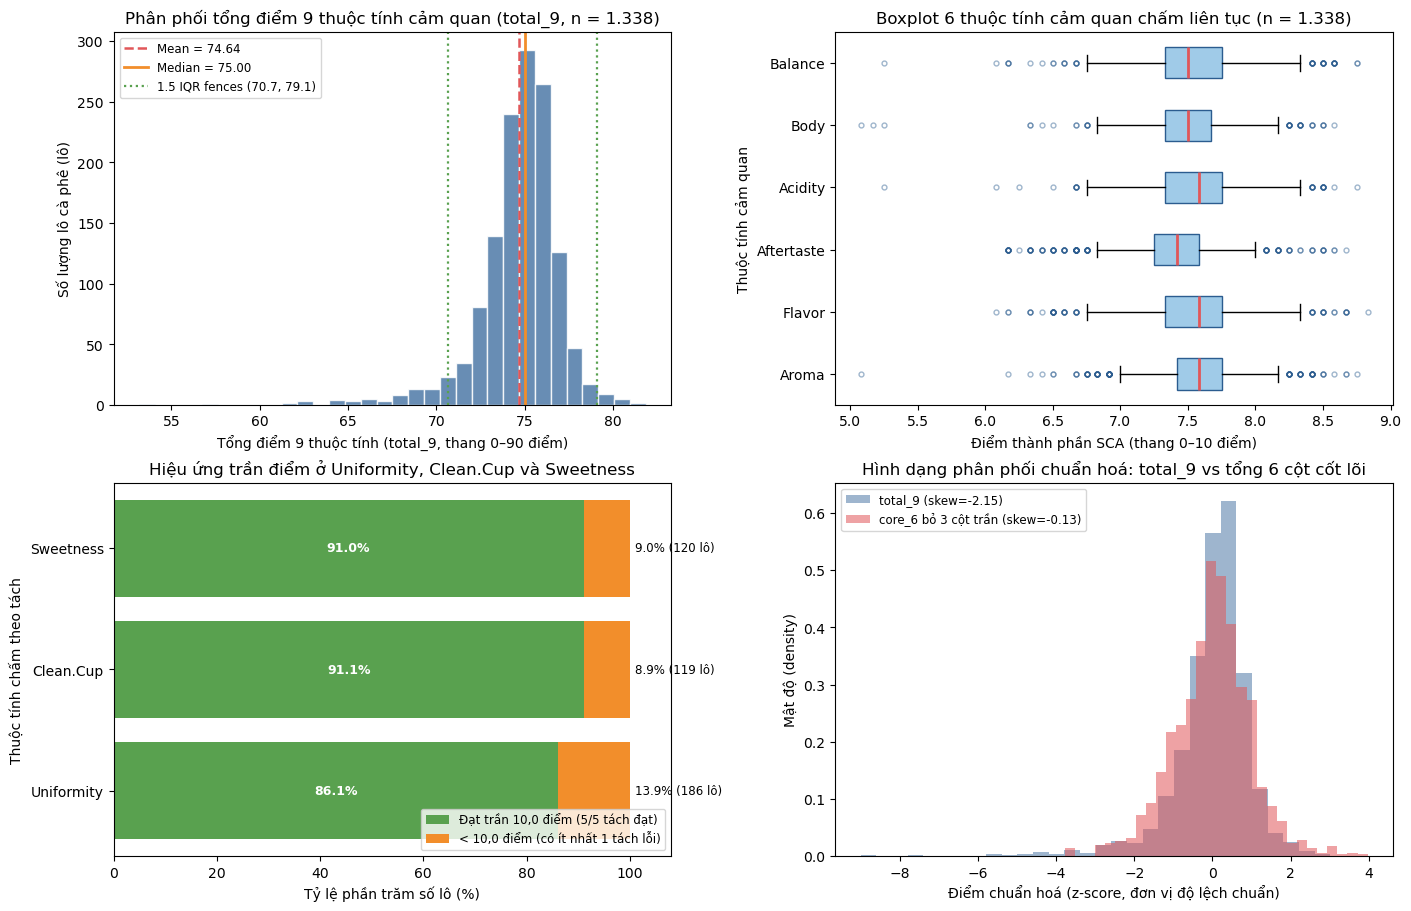

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), layout="constrained")

# 1. Histogram của total_9 kèm mean, median và ngưỡng 1.5 IQR
ax = axes[0, 0]
s_tot = df_num_valid["total_9"]
q1_t, q3_t = s_tot.quantile([0.25, 0.75])
iqr_t = q3_t - q1_t
ax.hist(s_tot, bins=32, color="#4E79A7", edgecolor="white", alpha=0.85)
ax.axvline(s_tot.mean(), color="#E15759", linestyle="--", linewidth=1.8, label=f"Mean = {s_tot.mean():.2f}")
ax.axvline(s_tot.median(), color="#F28E2B", linestyle="-", linewidth=2.0, label=f"Median = {s_tot.median():.2f}")
ax.axvline(q1_t - 1.5 * iqr_t, color="#59A14F", linestyle=":", linewidth=1.6, label=f"1.5 IQR fences ({q1_t - 1.5*iqr_t:.1f}, {q3_t + 1.5*iqr_t:.1f})")
ax.axvline(q3_t + 1.5 * iqr_t, color="#59A14F", linestyle=":", linewidth=1.6)
ax.set_title("Phân phối tổng điểm 9 thuộc tính cảm quan (total_9, n = 1.338)")
ax.set_xlabel("Tổng điểm 9 thuộc tính (total_9, thang 0–90 điểm)")
ax.set_ylabel("Số lượng lô cà phê (lô)")
ax.legend(fontsize=8.5)

# 2. Boxplot của 6 thuộc tính cảm quan liên tục
ax = axes[0, 1]
core6_cols = ["Aroma", "Flavor", "Aftertaste", "Acidity", "Body", "Balance"]
bp = ax.boxplot(
    [df_num_valid[c].dropna() for c in core6_cols],
    labels=core6_cols,
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="#A0CBE8", edgecolor="#2B5C8F"),
    medianprops=dict(color="#E15759", linewidth=2),
    flierprops=dict(marker="o", markersize=3.5, alpha=0.45, markeredgecolor="#2B5C8F"),
)
ax.set_title("Boxplot 6 thuộc tính cảm quan chấm liên tục (n = 1.338)")
ax.set_xlabel("Điểm thành phần SCA (thang 0–10 điểm)")
ax.set_ylabel("Thuộc tính cảm quan")

# 3. Tỷ lệ đạt trần điểm 10.0 vs < 10.0 của 3 thuộc tính chấm theo tách
ax = axes[1, 0]
ceiling_cols = ["Uniformity", "Clean.Cup", "Sweetness"]
pct_10 = [(df_num_valid[c] == 10.0).mean() * 100 for c in ceiling_cols]
pct_lt10 = [(df_num_valid[c] < 10.0).mean() * 100 for c in ceiling_cols]
y_pos = np.arange(len(ceiling_cols))
b1 = ax.barh(y_pos, pct_10, color="#59A14F", label="Đạt trần 10,0 điểm (5/5 tách đạt)")
b2 = ax.barh(y_pos, pct_lt10, left=pct_10, color="#F28E2B", label="< 10,0 điểm (có ít nhất 1 tách lỗi)")
ax.set_yticks(y_pos, ceiling_cols)
ax.set_xlim(0, 108)
ax.set_xlabel("Tỷ lệ phần trăm số lô (%)")
ax.set_ylabel("Thuộc tính chấm theo tách")
ax.set_title("Hiệu ứng trần điểm ở Uniformity, Clean.Cup và Sweetness")
for idx, (p10, plt10) in enumerate(zip(pct_10, pct_lt10)):
    ax.text(p10 / 2, idx, f"{p10:.1f}%", va="center", ha="center", color="white", fontweight="bold", fontsize=9)
    ax.text(p10 + plt10 + 1, idx, f"{plt10:.1f}% ({int(round(plt10*len(df_num_valid)/100))} lô)", va="center", fontsize=8.5)
ax.legend(loc="lower right", fontsize=8.5)

# 4. So sánh phân phối tổng 6 cột cốt lõi (core_6) vs tổng 9 cột (total_9) chuẩn hoá z-score
ax = axes[1, 1]
core_6_sum = df_num_valid[core6_cols].sum(axis=1)
z_tot9 = (s_tot - s_tot.mean()) / s_tot.std()
z_core6 = (core_6_sum - core_6_sum.mean()) / core_6_sum.std()
ax.hist(z_tot9, bins=30, alpha=0.55, color="#4E79A7", label=f"total_9 (skew={s_tot.skew():.2f})", density=True)
ax.hist(z_core6, bins=30, alpha=0.55, color="#E15759", label=f"core_6 bỏ 3 cột trần (skew={core_6_sum.skew():.2f})", density=True)
ax.set_title("Hình dạng phân phối chuẩn hoá: total_9 vs tổng 6 cột cốt lõi")
ax.set_xlabel("Điểm chuẩn hoá (z-score, đơn vị độ lệch chuẩn)")
ax.set_ylabel("Mật độ (density)")
ax.legend(fontsize=8.5)

plt.show()

#### d. Phân tích chuyên sâu 4 biến vật lý & lỗi hạt (`Moisture`, `Quakers`, `Category.One.Defects`, `Category.Two.Defects`)

4 biến vật lý đóng vai trò trung tâm trong câu hỏi **Q3 (Đức Thịnh — vùng độ ẩm tối ưu & lỗi hạt, kiểm tra độ bền outlier D6)** và là các đặc trưng đầu vào hợp lệ trước khi cupping cho câu hỏi **Q2 (ML — Ngọc Hoàng)**.

Đặc biệt, cần kiểm tra kỹ hai hiện tượng:
1. **Cụm 264 lô có `Moisture = 0.00` (19,73% mẫu):** Hạt cà phê nhân xanh trong điều kiện tự nhiên luôn có độ ẩm vật lý khoảng `8%–14%` (`0.08–0.14`); độ ẩm bằng `0%` tuyệt đối là **không khả thi về mặt sinh lý hạt** (chỉ xảy ra nếu sấy kiệt hoàn toàn trong phòng thí nghiệm). Do đó, `Moisture = 0.00` rất có khả năng là **giá trị quy ước khi không đo độ ẩm lúc nhập kho CQI**.
2. **Phân phối lệch phải rất mạnh của 3 cột lỗi hạt (`Quakers`, `Category.One.Defects`, `Category.Two.Defects`):** Đa số các lô đạt chuẩn đặc sản có `0` lỗi sơ cấp (`84,90%`) và `0` hạt quakers (`92,97%`), khiến `IQR = 0`. Vì vậy, quy tắc `1.5 IQR` đánh dấu mọi lô có `>= 1` lỗi là "outlier", dù trên thực tế đó là các lô cà phê có lỗi hạt thật.

In [36]:
# So sánh thống kê Moisture khi giữ nguyên 264 số 0 vs khi xem Moisture == 0 là khuyết (chỉ xét Moisture > 0)
moisture_all = df_num_valid["Moisture"]
moisture_pos = df_num_valid.loc[df_num_valid["Moisture"] > 0, "Moisture"]

moisture_compare = pd.DataFrame([
    {
        "Kịch bản": "Giữ toàn bộ (gồm 264 lô Moisture = 0.00)",
        "n_lots": len(moisture_all),
        "mean": moisture_all.mean(),
        "median": moisture_all.median(),
        "std": moisture_all.std(),
        "Q1": moisture_all.quantile(0.25),
        "Q3": moisture_all.quantile(0.75),
        "IQR": moisture_all.quantile(0.75) - moisture_all.quantile(0.25),
        "fence_low_1.5IQR": moisture_all.quantile(0.25) - 1.5 * (moisture_all.quantile(0.75) - moisture_all.quantile(0.25)),
        "fence_high_1.5IQR": moisture_all.quantile(0.75) + 1.5 * (moisture_all.quantile(0.75) - moisture_all.quantile(0.25)),
    },
    {
        "Kịch bản": "Chỉ xét các lô có đo độ ẩm dương (Moisture > 0)",
        "n_lots": len(moisture_pos),
        "mean": moisture_pos.mean(),
        "median": moisture_pos.median(),
        "std": moisture_pos.std(),
        "Q1": moisture_pos.quantile(0.25),
        "Q3": moisture_pos.quantile(0.75),
        "IQR": moisture_pos.quantile(0.75) - moisture_pos.quantile(0.25),
        "fence_low_1.5IQR": moisture_pos.quantile(0.25) - 1.5 * (moisture_pos.quantile(0.75) - moisture_pos.quantile(0.25)),
        "fence_high_1.5IQR": moisture_pos.quantile(0.75) + 1.5 * (moisture_pos.quantile(0.75) - moisture_pos.quantile(0.25)),
    },
])
print("Đối chiếu phân phối Moisture trước và sau khi tách 264 lô có Moisture = 0.00:")
display(moisture_compare.round(4))

# Kiểm tra các lô có lỗi hạt cực đoan nhất để xác minh là dữ liệu thật hay lỗi nhập liệu
print("\nTop 5 lô có Category.One.Defects cao nhất (kèm điểm total_9 để đối chiếu):")
display(
    df_num_valid.nlargest(5, "Category.One.Defects")[
        ["REC_ID", "Species", "Country.of.Origin", "Harvest.Year", "Category.One.Defects", "Category.Two.Defects", "Quakers", "total_9"]
    ]
)
print("\nTop 5 lô có Category.Two.Defects cao nhất:")
display(
    df_num_valid.nlargest(5, "Category.Two.Defects")[
        ["REC_ID", "Species", "Country.of.Origin", "Harvest.Year", "Category.One.Defects", "Category.Two.Defects", "Quakers", "total_9"]
    ]
)

Đối chiếu phân phối Moisture trước và sau khi tách 264 lô có Moisture = 0.00:


,Kịch bản,n_lots,mean,median,std,Q1,Q3,IQR,fence_low_1.5IQR,fence_high_1.5IQR
0,Giữ toàn bộ (gồm 264 lô Moisture = 0.00),1338,0.0884,0.11,0.0483,0.09,0.12,0.03,0.045,0.165
1,Chỉ xét các lô có đo độ ẩm dương (Moisture > 0),1074,0.1101,0.11,0.0227,0.10,0.12,0.02,0.070,0.150



Top 5 lô có Category.One.Defects cao nhất (kèm điểm total_9 để đối chiếu):


,REC_ID,Species,Country.of.Origin,Harvest.Year,Category.One.Defects,Category.Two.Defects,Quakers,total_9
1338,1338,Robusta,Vietnam,2013.0,63,9,0,65.83
536,536,Arabica,Taiwan,2016.0,31,0,0,75.17
1229,1229,Arabica,Mexico,2012.0,31,47,0,71.08
1279,1279,Arabica,Mexico,2012.0,23,29,0,68.43
1337,1337,Robusta,India,2013.0,20,1,0,68.16



Top 5 lô có Category.Two.Defects cao nhất:


,REC_ID,Species,Country.of.Origin,Harvest.Year,Category.One.Defects,Category.Two.Defects,Quakers,total_9
1302,1302,Arabica,Brazil,2017.0,0,55,1,63.99
1229,1229,Arabica,Mexico,2012.0,31,47,0,71.08
1195,1195,Arabica,Mexico,2012.0,0,45,0,72.16
250,250,Arabica,Ethiopia,2013.0,4,40,0,76.17
1203,1203,Arabica,Mexico,2012.0,7,38,0,72.17


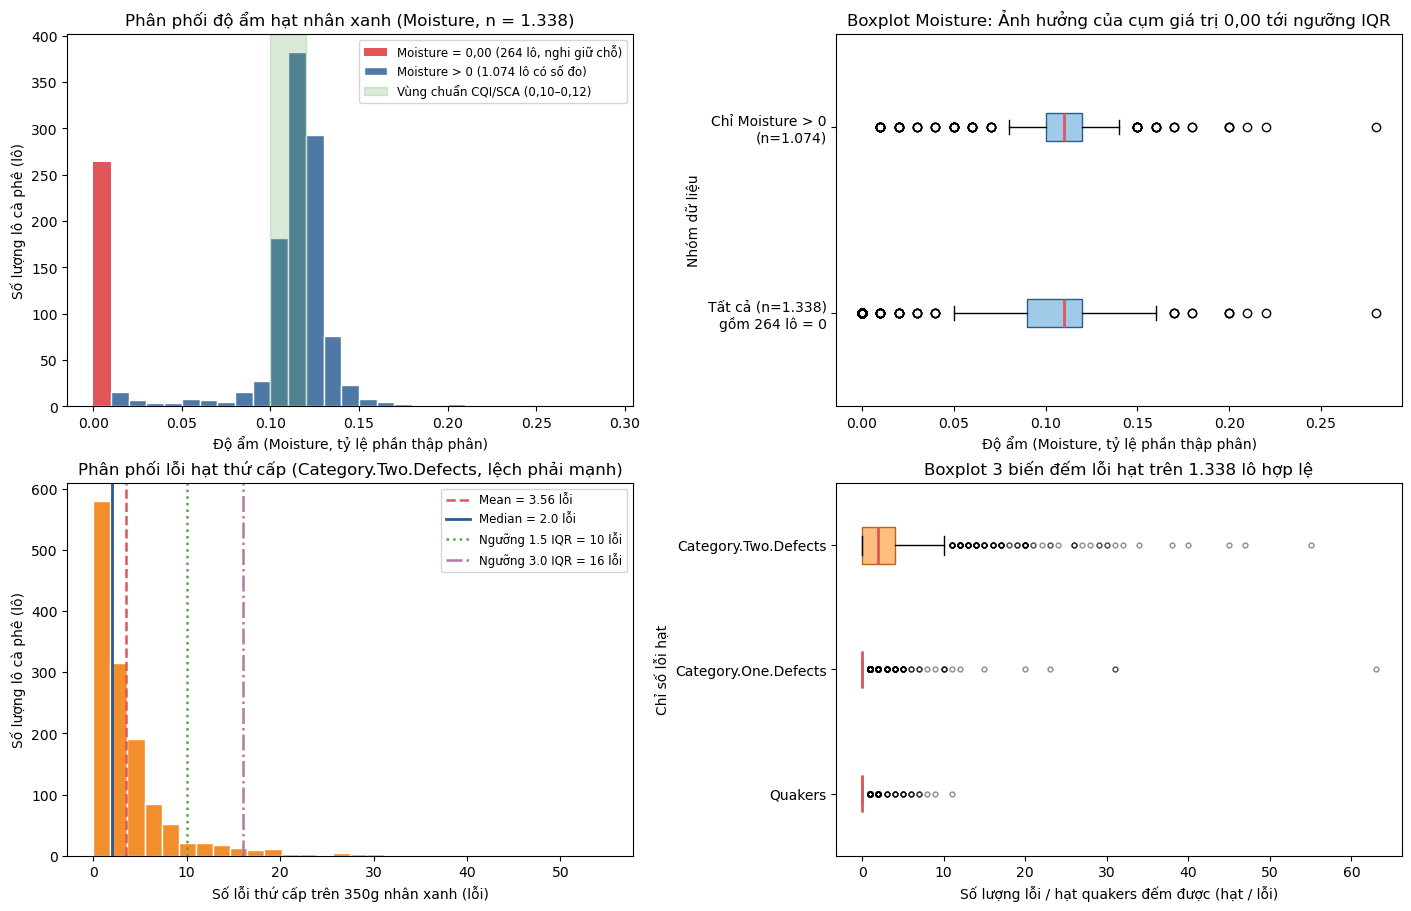

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), layout="constrained")

# 1. Phân phối Moisture (đánh dấu cụm 0.00 và vùng chuẩn bảo quản 0.10 - 0.12)
ax = axes[0, 0]
bins_m = np.linspace(0, 0.29, 30)
ax.hist(df_num_valid.loc[df_num_valid["Moisture"] == 0, "Moisture"], bins=bins_m, color="#E15759", label="Moisture = 0,00 (264 lô, nghi giữ chỗ)")
ax.hist(df_num_valid.loc[df_num_valid["Moisture"] > 0, "Moisture"], bins=bins_m, color="#4E79A7", edgecolor="white", label="Moisture > 0 (1.074 lô có số đo)")
ax.axvspan(0.10, 0.12, color="#59A14F", alpha=0.22, label="Vùng chuẩn CQI/SCA (0,10–0,12)")
ax.set_title("Phân phối độ ẩm hạt nhân xanh (Moisture, n = 1.338)")
ax.set_xlabel("Độ ẩm (Moisture, tỷ lệ phần thập phân)")
ax.set_ylabel("Số lượng lô cà phê (lô)")
ax.legend(fontsize=8.5)

# 2. Boxplot Moisture: Toàn bộ vs Moisture > 0
ax = axes[0, 1]
ax.boxplot(
    [moisture_all, moisture_pos],
    labels=["Tất cả (n=1.338)\ngồm 264 lô = 0", "Chỉ Moisture > 0\n(n=1.074)"],
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="#A0CBE8", edgecolor="#2B5C8F"),
    medianprops=dict(color="#E15759", linewidth=2),
)
ax.set_title("Boxplot Moisture: Ảnh hưởng của cụm giá trị 0,00 tới ngưỡng IQR")
ax.set_xlabel("Độ ẩm (Moisture, tỷ lệ phần thập phân)")
ax.set_ylabel("Nhóm dữ liệu")

# 3. Phân phối Category.Two.Defects
ax = axes[1, 0]
s_cat2 = df_num_valid["Category.Two.Defects"]
q1_c2, q3_c2 = s_cat2.quantile([0.25, 0.75])
iqr_c2 = q3_c2 - q1_c2
ax.hist(s_cat2, bins=30, color="#F28E2B", edgecolor="white")
ax.axvline(s_cat2.mean(), color="#E15759", linestyle="--", linewidth=1.8, label=f"Mean = {s_cat2.mean():.2f} lỗi")
ax.axvline(s_cat2.median(), color="#2B5C8F", linestyle="-", linewidth=2.0, label=f"Median = {s_cat2.median():.1f} lỗi")
ax.axvline(q3_c2 + 1.5 * iqr_c2, color="#59A14F", linestyle=":", linewidth=1.8, label=f"Ngưỡng 1.5 IQR = {q3_c2 + 1.5*iqr_c2:.0f} lỗi")
ax.axvline(q3_c2 + 3.0 * iqr_c2, color="#B07AA1", linestyle="-.", linewidth=1.8, label=f"Ngưỡng 3.0 IQR = {q3_c2 + 3.0*iqr_c2:.0f} lỗi")
ax.set_title("Phân phối lỗi hạt thứ cấp (Category.Two.Defects, lệch phải mạnh)")
ax.set_xlabel("Số lỗi thứ cấp trên 350g nhân xanh (lỗi)")
ax.set_ylabel("Số lượng lô cà phê (lô)")
ax.legend(fontsize=8.5)

# 4. Boxplot so sánh 3 biến đếm lỗi hạt (Category.One.Defects, Category.Two.Defects, Quakers)
ax = axes[1, 1]
defect_cols = ["Quakers", "Category.One.Defects", "Category.Two.Defects"]
ax.boxplot(
    [df_num_valid[c] for c in defect_cols],
    labels=defect_cols,
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="#FFBE7D", edgecolor="#B66325"),
    medianprops=dict(color="#E15759", linewidth=2),
    flierprops=dict(marker="o", markersize=3.5, alpha=0.45),
)
ax.set_title("Boxplot 3 biến đếm lỗi hạt trên 1.338 lô hợp lệ")
ax.set_xlabel("Số lượng lỗi / hạt quakers đếm được (hạt / lỗi)")
ax.set_ylabel("Chỉ số lỗi hạt")

plt.show()

In [38]:
# TEST — Kiểm tra tính chính xác của mục 3.2.2 Numerical columns
assert len(df_num_valid) == 1338, "Mẫu hợp lệ sau khi bỏ REC_ID=1310 phải có đúng 1.338 lô"
assert int((df["REC_ID"] == 1310).sum()) == 1, "REC_ID=1310 phải tồn tại trong df gốc"
assert (df.loc[df["REC_ID"] == 1310, SCORE_COLS] == 0).all(axis=None), "REC_ID=1310 có cả 9 điểm bằng 0"
assert int((df_num_valid["Moisture"] == 0).sum()) == 264, "Phải có đúng 264 lô có Moisture = 0.00"
assert outlier_table.loc["Category.Two.Defects", "n_total_1.5IQR"] == 94, "Category.Two.Defects có 94 outlier theo 1.5 IQR"
assert outlier_table.loc["Category.Two.Defects", "n_total_3.0IQR"] == 43, "Category.Two.Defects có 43 outlier theo 3.0 IQR"
print("Numerical columns checks passed")

Numerical columns checks passed


#### Nhận xét — Numerical columns

- **Bản ghi giữ chỗ `REC_ID = 1310` và sự thay đổi hình dạng phân phối:**
  - Trên toàn bộ `1.339` lô, duy nhất bản ghi `REC_ID = 1310` (Honduras, 2017) có cả 9 điểm cảm quan bằng `0.00` (`total_9 = 0.00`), làm hệ số lệch của `total_9` bị kéo xuống `-10,954` và độ nhọn vọt lên `240,911`.
  - Sau khi loại `REC_ID = 1310` (còn `1.338` lô), `total_9` có `mean = 74,642` điểm, `median = 75,000` điểm (`mean - median = -0,358` điểm), `IQR = 2,098` điểm (từ `73,822` đến `75,920`), `min = 53,17` và `max = 81,84`. Độ lệch giảm mạnh về `-2,152` (phân phối hơi lệch trái do một số lô chất lượng thấp thật sự ở vùng `53–68` điểm).
- **Hai nhóm thuộc tính cảm quan có hành vi thống kê đối lập:**
  - **6 thuộc tính chấm liên tục (`Aroma`, `Flavor`, `Aftertaste`, `Acidity`, `Body`, `Balance`):** Có phân phối gần đối xứng quanh vùng `7,40–7,58` điểm (`|skew| < 1,0`, `mean` và `median` chênh nhau không quá `0,06` điểm), `IQR` ổn định từ `0,33` đến `0,42` điểm. Đây là những biến phân biệt chất lượng thực chất nhất giữa các lô.
  - **3 thuộc tính chấm theo tách (`Uniformity`, `Clean.Cup`, `Sweetness`):** Bị **hiệu ứng trần điểm (ceiling effect)** nghiêm trọng — lần lượt `86,10%` (`1.152` lô), `91,11%` (`1.219` lô) và `91,03%` (`1.218` lô) nhận điểm tối đa `10,00`. Vì `Q1 = Q3 = 10,00` (`IQR = 0`), mọi lô bị trừ điểm dù chỉ 1 tách (`8,00` điểm) đều bị quy tắc `1.5 IQR` gắn nhãn "outlier" (`186`, `119` và `120` lô). Phát hiện này là cơ sở trực tiếp để **Câu hỏi Q6 (Tùng Hiếu)** kiểm tra độ bền của hồ sơ hương vị khi giữ nguyên 9 cột so với khi loại bỏ 3 cột trần điểm.
- **Độ ẩm (`Moisture`) có cấu trúc hai đỉnh (bimodal) do 264 giá trị `0,00`:**
  - Nếu tính trên cả `1.338` lô, `Moisture` có `mean = 0,088` thấp hơn hẳn `median = 0,110` do bị kéo bởi **264 lô (`19,73%`) có `Moisture = 0,00`**.
  - Khi tách riêng `264` lô bằng `0` (nghi là giá trị mặc định khi không đo độ ẩm) và chỉ xét `1.074` lô có `Moisture > 0`, phân phối trở nên cân đối hoàn hảo quanh vùng bảo quản tiêu chuẩn của SCA: `mean = 0,1101`, `median = 0,1100`, `Q1 = 0,1000`, `Q3 = 0,1200` (`IQR = 0,0200`), với `858/1.074` lô (`79,89%`) nằm đúng trong dải chuẩn `10%–12%` (`0,10–0,12`).
- **Kết luận về Outlier ở các cột lỗi hạt (`Category.One.Defects`, `Category.Two.Defects`, `Quakers`):**
  - Cả 3 biến đều là biến đếm lệch phải mạnh (`skew` từ `3,665` đến `15,056`): `84,90%` số lô không có lỗi sơ cấp (`Category.One.Defects = 0`), `92,97%` số lô không có hạt `Quakers = 0`, và `median` của `Category.Two.Defects` là `2,0` lỗi (`mean = 3,558` lỗi).
  - Kiểm tra trực tiếp các lô có lỗi cao nhất (như `REC_ID = 1338` có `63` lỗi sơ cấp, `total_9 = 65,83`; `REC_ID = 1302` có `55` lỗi thứ cấp, `total_9 = 63,99`; `REC_ID = 1229` có `31` lỗi sơ cấp và `47` lỗi thứ cấp, `total_9 = 71,08`) cho thấy điểm cảm quan của chúng đều thấp tương ứng. Do đó, **đây là những lô cà phê nhiều lỗi hạt thật sự trong thực tế, KHÔNG phải lỗi nhập liệu**. Nhóm tuyệt đối không xoá cứng các dòng này ở bước EDA; thay vào đó, ở **Câu hỏi Q3 (Đức Thịnh)**, nhóm sẽ đối chiếu kết quả trên toàn bộ mẫu với kết quả khi lọc theo ngưỡng `1.5 IQR` (`> 10` lỗi thứ cấp, `94` lô) và `3.0 IQR` (`> 16` lỗi thứ cấp, `43` lô) để đáp ứng tiêu chí **D6 (Robustness check)**.

### 3.2.3. Categorical columns
*(Tùng Hiếu — `feat/eda-categorical`)*

**Mục tiêu:** kiểm kê Species, Continent.of.Origin, Country.of.Origin, Variety, Color và Processing.Method trước khi chuẩn hoá, gộp nhóm hiếm hoặc lọc loài.

Mỗi dòng đầu vào được xem là một bản ghi lô cà phê. Phần này giữ nguyên tất cả dòng và nhãn. Ô trống được đọc thành giá trị thiếu; chuỗi `"None"` vẫn là một nhãn riêng cần xác minh.

#### a. Số nhãn, độ thiếu và mức tập trung

`n_unique_nonmissing` không tính giá trị thiếu. Các tỷ lệ trong bảng tổng quan đều có mẫu số là **toàn bộ số dòng đầu vào**. Độ tập trung được mô tả bằng tỷ lệ nhãn phổ biến nhất, chưa phải tiêu chuẩn tự động bỏ cột.

In [39]:
from IPython.display import HTML


def display_centered_table(table):
    """Center column headings and values in the displayed table."""
    html = table.to_html(notebook=True)
    html = html.replace("<th>", '<th style="text-align: center !important;">')
    html = html.replace("<td>", '<td style="text-align: center !important;">')
    display(HTML(html))


missing_columns = set(CAT_COLS) - set(df.columns)
if missing_columns:
    raise ValueError(f"Thiếu các cột bắt buộc: {sorted(missing_columns)}")
if df.empty:
    raise ValueError("Dữ liệu đầu vào không có dòng.")

n_rows = len(df)
summary_rows = []
for column in CAT_COLS:
    counts = df[column].value_counts(dropna=True)
    top_label = counts.index[0] if not counts.empty else pd.NA
    top_count = int(counts.iloc[0]) if not counts.empty else 0
    summary_rows.append({
        "column": column,
        "n_unique_nonmissing": df[column].nunique(dropna=True),
        "n_missing": int(df[column].isna().sum()),
        "missing_pct_all": df[column].isna().mean() * 100,
        "top_label": top_label,
        "top_n": top_count,
        "top_pct_all": top_count / n_rows * 100,
    })
cat_summary = pd.DataFrame(summary_rows).set_index("column")
display_centered_table(cat_summary.reset_index().round(2))

,column,n_unique_nonmissing,n_missing,missing_pct_all,top_label,top_n,top_pct_all
0,Species,2,0,0.00,Arabica,1311,97.91
1,Continent.of.Origin,5,1,0.07,North America,665,49.66
2,Country.of.Origin,34,1,0.07,Mexico,236,17.63
3,Variety,29,226,16.88,Caturra,256,19.12
4,Color,4,218,16.28,Green,870,64.97
5,Processing.Method,5,170,12.70,Washed / Wet,815,60.87


#### b. Top 5 của từng cột

Mỗi bảng trình bày tối đa 5 **nhãn đã biết**, sắp theo số lô giảm dần. `pct_all` tính trên toàn bộ dòng, `pct_known` tính riêng các dòng không thiếu của cột. Tổng phần trăm top 5 có thể nhỏ hơn 100% vì còn nhãn khác và dữ liệu thiếu. Số thiếu được báo riêng trong bảng tổng quan.

In [40]:
top5_tables = {}
for column in CAT_COLS:
    counts = df[column].value_counts(dropna=True)
    known_n = int(df[column].notna().sum())
    table = counts.head(5).rename_axis("label").reset_index(name="n_lots")
    table.insert(0, "rank", range(1, len(table) + 1))
    table["pct_all"] = table["n_lots"] / n_rows * 100
    table["pct_known"] = table["n_lots"] / known_n * 100 if known_n else float("nan")
    top5_tables[column] = table
    print(f"{column} — đã biết: {known_n:,}; thiếu: {n_rows - known_n:,}")
    display_centered_table(table.round(2).rename(columns={"n_lots": "Number of coffee lots"}))

Species — đã biết: 1,339; thiếu: 0


,rank,label,Number of coffee lots,pct_all,pct_known
0,1,Arabica,1311,97.91,97.91
1,2,Robusta,28,2.09,2.09


Continent.of.Origin — đã biết: 1,338; thiếu: 1


,rank,label,Number of coffee lots,pct_all,pct_known
0,1,North America,665,49.66,49.70
1,2,South America,328,24.50,24.51
2,3,Asia,182,13.59,13.60
3,4,Africa,162,12.10,12.11
4,5,Oceania,1,0.07,0.07


Country.of.Origin — đã biết: 1,338; thiếu: 1


,rank,label,Number of coffee lots,pct_all,pct_known
0,1,Mexico,236,17.63,17.64
1,2,Colombia,183,13.67,13.68
2,3,Guatemala,181,13.52,13.53
3,4,Brazil,132,9.86,9.87
4,5,United States,87,6.50,6.50


... (2 outputs left out)

Color — đã biết: 1,121; thiếu: 218


,rank,label,Number of coffee lots,pct_all,pct_known
0,1,Green,870,64.97,77.61
1,2,Bluish-Green,114,8.51,10.17
2,3,Blue-Green,85,6.35,7.58
3,4,None,52,3.88,4.64


Processing.Method — đã biết: 1,169; thiếu: 170


,rank,label,Number of coffee lots,pct_all,pct_known
0,1,Washed / Wet,815,60.87,69.72
1,2,Natural / Dry,258,19.27,22.07
2,3,Semi-washed / Semi-pulped,56,4.18,4.79
3,4,Other,26,1.94,2.22
4,5,Pulped natural / honey,14,1.05,1.20


#### c. Cơ cấu Species và phương án phân tích

Biểu đồ dùng toàn bộ dữ liệu đầu vào để đánh giá mức mất cân bằng. Đây là bằng chứng để thảo luận phạm vi phân tích; phần này **chưa loại Robusta**. Nếu cần nhận xét về khác biệt quy trình/thang chấm giữa hai loài, phải bổ sung nguồn chuyên môn trước khi dùng làm lý do lọc.

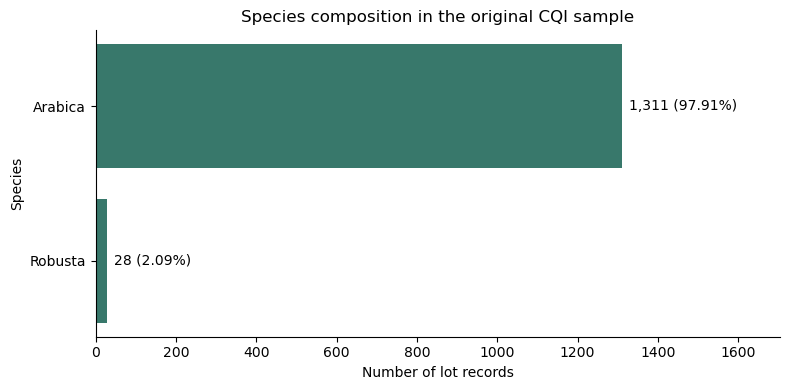

In [41]:
species_counts = df["Species"].fillna("Missing").value_counts()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(species_counts.index, species_counts.values, color="#38786b")
ax.invert_yaxis()
ax.set_title("Species composition in the original CQI sample")
ax.set_xlabel("Number of lot records")
ax.set_ylabel("Species")
ax.set_xlim(0, species_counts.max() * 1.3)
ax.bar_label(bars, labels=[f"{n:,} ({n / n_rows:.2%})" for n in species_counts], padding=5)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

#### d. Độ tập trung và các nhóm ít lô

Bảng dưới bổ sung tỷ lệ nhãn đứng đầu trên các lô có nhãn và số nhóm dưới 20 lô.

In [42]:
balance_rows = []
for column in CAT_COLS:
    counts = df[column].value_counts(dropna=True)
    known_n = int(counts.sum())
    balance_rows.append({
        "column": column,
        "top_pct_known": counts.iloc[0] / known_n * 100 if known_n else float("nan"),
        "n_categories_lt20": int(counts.lt(20).sum()),
        "n_lots_in_categories_lt20": int(counts[counts.lt(20)].sum()),
    })
display_centered_table(pd.DataFrame(balance_rows).round(2))

arabica_mask = df["Species"].eq("Arabica")
scope_options = pd.DataFrame([
    {"scope": "All species (current)", "n_lots": n_rows, "retained_pct": 100.0},
    {"scope": "Arabica only (proposal)", "n_lots": int(arabica_mask.sum()),
     "retained_pct": arabica_mask.mean() * 100},
])
display_centered_table(scope_options.round(2).rename(columns={"n_lots": "Number of coffee lots"}))
print("Chưa áp dụng bộ lọc Species. Cần nhóm thống nhất phạm vi trước khi lọc.")

,column,top_pct_known,n_categories_lt20,n_lots_in_categories_lt20
0,Species,97.91,0,0
1,Continent.of.Origin,49.70,1,1
2,Country.of.Origin,17.64,18,96
3,Variety,23.00,20,104
4,Color,77.61,0,0
5,Processing.Method,69.72,1,14


,scope,Number of coffee lots,retained_pct
0,All species (current),1339,100.00
1,Arabica only (proposal),1311,97.91


Chưa áp dụng bộ lọc Species. Cần nhóm thống nhất phạm vi trước khi lọc.


#### e. Kiểm tra tính nhất quán

Các kiểm tra sau xác nhận số đếm, mẫu số và nhãn `None` không bị mất do cách đọc file. Không có thao tác loại dòng trong mục này.

In [43]:
assert len(df) == n_rows
for column in CAT_COLS:
    assert df[column].value_counts().sum() + df[column].isna().sum() == n_rows
    table = top5_tables[column]
    assert len(table) <= 5
    assert table["n_lots"].sum() <= df[column].notna().sum()
    assert table["pct_all"].between(0, 100).all()
print(f"Đã kiểm tra {len(CAT_COLS)} cột; số dòng trước/sau: {n_rows:,}/{len(df):,}.")
print("Color literal 'None':", int(df["Color"].eq("None").sum()))

Đã kiểm tra 6 cột; số dòng trước/sau: 1,339/1,339.
Color literal 'None': 52


#### f. Chuẩn hoá nhãn — Bước 2

Quy trình: tạo bản sao `df_labels` từ `df`; chỉ sửa 6 cột phân loại bằng `src/labels.py`. Cắt và thu gọn khoảng trắng, đưa về chữ thường bằng `casefold`, rồi áp dụng ánh xạ quốc gia tường minh. Không lọc dòng, không sửa cột số, không tự gộp các tên giống cà phê, màu sắc hoặc cách sơ chế chỉ vì cách viết gần nhau.

Giữ `df` để đối chiếu. Literal `Color="None"` thành nhãn `"none"`, vẫn khác giá trị thiếu. `Other` thành `other`, vẫn khác nhóm do thuật toán gộp. Bảng ánh xạ quốc gia ở đây chưa phải ánh xạ sang tên FAOSTAT; không tự gộp Hawaii hoặc vùng lãnh thổ vào quốc gia.

Bảng trước/sau tập trung vào Country, Variety, Processing theo phân công, đồng thời kiểm tra số thiếu và số dòng. Việc đổi cách viết không nhất thiết làm giảm số nhãn.

In [44]:
# Mọi lần chạy lại đều bắt đầu từ dữ liệu gốc.
df_labels = normalize_labels(df)
REVIEW_COLS = ["Country.of.Origin", "Variety", "Processing.Method"]
normalization_summary = pd.DataFrame([
    {
        "column": column,
        "unique_before": df[column].nunique(dropna=True),
        "unique_after": df_labels[column].nunique(dropna=True),
        "missing_before": int(df[column].isna().sum()),
        "missing_after": int(df_labels[column].isna().sum()),
        "changed_rows": int(
            df[column].astype("string").fillna("<MISSING>")
            .ne(df_labels[column].fillna("<MISSING>")).sum()
        ),
    }
    for column in REVIEW_COLS
]).set_index("column")
display_centered_table(normalization_summary.reset_index())
print(f"Chuẩn hoá: {len(df):,} → {len(df_labels):,} dòng; không lọc dòng.")

,column,unique_before,unique_after,missing_before,missing_after,changed_rows
0,Country.of.Origin,34,34,1,1,1338
1,Variety,29,29,226,226,1113
2,Processing.Method,5,5,170,170,1169


Chuẩn hoá: 1,339 → 1,339 dòng; không lọc dòng.


**Kiểm toán nhãn:** bảng dưới liệt kê từng nhãn thực tế trước/sau cùng số lô, kể cả trường hợp không thay đổi. Bảng alias chỉ hiện các quy tắc thực sự khớp trong bản dữ liệu đang đọc; không coi quy tắc chưa xuất hiện là lỗi đã quan sát.

In [45]:
label_audits = {}
for column in REVIEW_COLS:
    pairs = pd.DataFrame({
        "before": df[column].astype("string"),
        "after": df_labels[column],
    })
    audit = pairs.groupby(["before", "after"], dropna=False).size().reset_index(name="n_lots")
    audit = audit.sort_values(["n_lots", "before"], ascending=[False, True]).reset_index(drop=True)
    label_audits[column] = audit
    print(column)
    display_centered_table(audit.rename(columns={"n_lots": "Number of coffee lots"}))

country_base = (df["Country.of.Origin"].astype("string").str.strip()
                .str.replace(r"\s+", " ", regex=True).str.casefold())
alias_usage = pd.DataFrame([
    {"from": old, "to": new, "n_lots": int(country_base.eq(old).sum())}
    for old, new in COUNTRY_ALIASES.items()
    if country_base.eq(old).any()
])
print("Alias quốc gia thực sự được áp dụng:")
display_centered_table(alias_usage.rename(columns={"n_lots": "Number of coffee lots"}))

Country.of.Origin


,before,after,Number of coffee lots
0,Mexico,mexico,236
1,Colombia,colombia,183
2,Guatemala,guatemala,181
3,Brazil,brazil,132
4,United States,united states,87
5,Taiwan,taiwan,75
6,Honduras,honduras,53
7,Costa Rica,costa rica,51
8,Ethiopia,ethiopia,44
9,Tanzania,tanzania,40


Variety


,before,after,Number of coffee lots
0,Caturra,caturra,256
1,Bourbon,bourbon,226
2,<NA>,<NA>,226
3,Typica,typica,211
4,Other,other,110
5,Catuai,catuai,74
6,Hawaiian Kona,hawaiian kona,44
7,Yellow Bourbon,yellow bourbon,35
8,Mundo Novo,mundo novo,33
9,Catimor,catimor,20


Processing.Method


,before,after,Number of coffee lots
0,Washed / Wet,washed / wet,815
1,Natural / Dry,natural / dry,258
2,<NA>,<NA>,170
3,Semi-washed / Semi-pulped,semi-washed / semi-pulped,56
4,Other,other,26
5,Pulped natural / honey,pulped natural / honey,14


Alias quốc gia thực sự được áp dụng:


,from,to,Number of coffee lots
0,cote divoire,cote d'ivoire,1


#### g. Gộp nhãn hiếm để trình bày

Theo kế hoạch tuần 1, dùng `min_n=20`: nhãn có **ít hơn 20 lô** trong toàn bộ mẫu hiện tại được gộp; nhãn có đúng 20 lô được giữ. Đây là ngưỡng thực hành nhằm giảm các nhóm quá nhỏ khi trình bày, không phải bằng chứng rằng mọi median từ 20 lô trở lên đều ổn định.

Tạo các cột mới có hậu tố `__grouped` trong `df_grouped` cho Country, Variety, Processing. Nhãn chuẩn hoá vẫn được giữ để nối FAOSTAT và phân tích chi tiết. Không dùng quốc gia đã gộp làm khoá nối. Nhãn thiếu giữ nguyên; `Other (rare)` chỉ các nhóm do thuật toán gộp, khác nhãn `other` có sẵn.

Không áp dụng gộp cho Species, Continent hoặc Color ở bước này. Nếu câu hỏi tập trung vào một nhóm hiếm (ví dụ honey processing), phải dùng cột chưa gộp hoặc xem xét quy tắc riêng. Nếu sau này lọc Arabica, cần tính lại tần suất trên mẫu mới. Nếu dùng cho ML, quy tắc tần suất phải được học riêng trên train.

In [46]:
MIN_N = 20
RARE_LABEL = "Other (rare)"
df_grouped = df_labels.copy(deep=True)
rare_summaries = []
rare_audits = {}
for column in REVIEW_COLS:
    counts = df_labels[column].value_counts(dropna=True)
    rare_counts = counts[counts.lt(MIN_N)]
    grouped_column = column + "__grouped"
    df_grouped[grouped_column] = group_rare(df_labels[column], min_n=MIN_N, other=RARE_LABEL)
    audit = rare_counts.rename_axis("original_label").reset_index(name="n_lots")
    audit["grouped_label"] = RARE_LABEL
    audit["pct_all"] = audit["n_lots"] / len(df_labels) * 100
    rare_audits[column] = audit
    rare_summaries.append({
        "column": column,
        "unique_before": df_labels[column].nunique(dropna=True),
        "unique_after": df_grouped[grouped_column].nunique(dropna=True),
        "n_rare_categories": len(rare_counts),
        "n_grouped_lots": int(rare_counts.sum()),
        "grouped_pct_all": rare_counts.sum() / len(df_labels) * 100,
        "missing_after": int(df_grouped[grouped_column].isna().sum()),
    })
    print(f"{column} — các nhãn được gộp:")
    display_centered_table(audit.round(2).rename(columns={"n_lots": "Number of coffee lots"}))
rare_summary = pd.DataFrame(rare_summaries).set_index("column")
display_centered_table(rare_summary.reset_index().round(2))
print(f"Gộp nhóm: {len(df_labels):,} → {len(df_grouped):,} dòng; chỉ thêm 3 cột trình bày.")

Country.of.Origin — các nhãn được gộp:


,original_label,Number of coffee lots,grouped_label,pct_all
0,china,16,Other (rare),1.19
1,india,14,Other (rare),1.05
2,malawi,11,Other (rare),0.82
3,peru,10,Other (rare),0.75
4,vietnam,8,Other (rare),0.6
5,myanmar,8,Other (rare),0.6
6,haiti,6,Other (rare),0.45
7,philippines,5,Other (rare),0.37
8,panama,4,Other (rare),0.3
9,ecuador,3,Other (rare),0.22


Variety — các nhãn được gộp:


,original_label,Number of coffee lots,grouped_label,pct_all
0,sl14,17,Other (rare),1.27
1,sl28,15,Other (rare),1.12
2,pacas,13,Other (rare),0.97
3,gesha,12,Other (rare),0.9
4,pacamara,8,Other (rare),0.6
5,sl34,8,Other (rare),0.6
6,arusha,6,Other (rare),0.45
7,peaberry,5,Other (rare),0.37
8,sumatra,3,Other (rare),0.22
9,mandheling,3,Other (rare),0.22


Processing.Method — các nhãn được gộp:


,original_label,Number of coffee lots,grouped_label,pct_all
0,pulped natural / honey,14,Other (rare),1.05


,column,unique_before,unique_after,n_rare_categories,n_grouped_lots,grouped_pct_all,missing_after
0,Country.of.Origin,34,17,18,96,7.17,1
1,Variety,29,10,20,104,7.77,226
2,Processing.Method,5,5,1,14,1.05,170


Gộp nhóm: 1,339 → 1,339 dòng; chỉ thêm 3 cột trình bày.


#### h. Kiểm tra ngưỡng và bảo toàn dữ liệu

So sánh 10, 20 và 30 để thấy mức mất chi tiết do ngưỡng gộp. Bảng này chỉ đánh giá tác động lên cơ cấu nhóm, chưa chứng minh một kết luận nghiên cứu bền vững. Trước khi dùng cột gộp cho câu hỏi cụ thể, thành viên cần giải thích lựa chọn và kiểm tra kết luận với cột chưa gộp.

Các kiểm tra bảo toàn xác nhận: số dòng/index, các cột không thuộc phạm vi chuẩn hoá, vị trí thiếu hiện tại và nhãn `none`/`other` không bị đánh đồng với nhóm hiếm.

In [47]:
threshold_rows = []
for column in REVIEW_COLS:
    counts = df_labels[column].value_counts(dropna=True)
    for threshold in [10, 20, 30]:
        grouped = group_rare(df_labels[column], min_n=threshold, other=RARE_LABEL)
        threshold_rows.append({
            "column": column, "min_n": threshold,
            "n_rare_categories": int(counts.lt(threshold).sum()),
            "n_grouped_lots": int(counts[counts.lt(threshold)].sum()),
            "n_categories_after": grouped.nunique(dropna=True),
        })
display_centered_table(pd.DataFrame(threshold_rows))

untouched_cols = [c for c in df.columns if c not in CAT_COLS]
pd.testing.assert_frame_equal(df_labels[untouched_cols], df[untouched_cols])
pd.testing.assert_index_equal(df_labels.index, df.index)
pd.testing.assert_frame_equal(normalize_labels(df_labels), df_labels)
assert len(df) == len(df_labels) == len(df_grouped)
for column in CAT_COLS:
    assert df[column].isna().equals(df_labels[column].isna())
for column in REVIEW_COLS:
    original = df_labels[column]
    grouped = df_grouped[column + "__grouped"]
    assert original.isna().equals(grouped.isna())
    pd.testing.assert_series_equal(df_grouped[column], original)
    assert grouped.eq(RARE_LABEL).sum() == rare_summary.loc[column, "n_grouped_lots"]
    # Nhãn Other có sẵn trong mẫu hiện tại đều >=20, nên được giữ riêng.
    assert grouped[original.eq("other").fillna(False)].eq("other").all()
assert df_labels["Color"].eq("none").sum() == df["Color"].eq("None").sum()
print("Đạt: không mất dòng, giữ cột gốc và giá trị thiếu; chuẩn hoá có tính lặp ổn định.")

,column,min_n,n_rare_categories,n_grouped_lots,n_categories_after
0,Country.of.Origin,10,14,45,21
1,Country.of.Origin,20,18,96,17
2,Country.of.Origin,30,22,188,13
3,Variety,10,16,47,14
4,Variety,20,20,104,10
5,Variety,30,21,124,9
6,Processing.Method,10,0,0,5
7,Processing.Method,20,1,14,5
8,Processing.Method,30,2,40,4


Đạt: không mất dòng, giữ cột gốc và giá trị thiếu; chuẩn hoá có tính lặp ổn định.


#### Nhận xét — Categorical columns

- **Species và xuất xứ:** Biểu đồ cho thấy Arabica chiếm 1.311/1.339 lô (97,91%), còn Robusta có 28 lô (2,09%). Nếu giới hạn EDA gốc ở Arabica, phạm vi kết luận sẽ là 1.311 lô Arabica. North America có 665 lô (49,66%), trong khi Oceania chỉ có 1 lô. Mexico, Colombia và Guatemala có tổng cộng 600 lô (44,81% mẫu). Mẫu này tập trung vào Arabica và một số nước có nhiều lô được CQI chấm điểm. Vì vậy, kết quả tính trên toàn bộ mẫu chịu ảnh hưởng nhiều hơn từ các nhóm đông lô. Riêng Oceania chỉ có một lô, nên không đủ dữ liệu để so sánh châu lục này với North America hay South America.
- **Nhãn phổ biến và giá trị thiếu:** Trong 1.339 lô, có 256 lô Caturra, chiếm 19,12%. Khi chỉ tính 1.113 lô có nhãn `Variety`, tỷ lệ này là 23,00%. Tương tự, 870 lô Green chiếm 64,97% trong 1.339 lô và 77,61% trong 1.121 lô có nhãn `Color`. Với `Processing.Method`, 815 lô Washed / Wet chiếm 60,87% trong toàn bộ 1.339 lô. Nếu bỏ 170 lô thiếu nhãn sơ chế, mẫu số còn 1.169 lô và tỷ lệ Washed / Wet là 69,72%. `Color` có 218 ô thiếu. Ngoài ra, 52 lô mang nhãn `None` được ghi sẵn trong CSV. Bảng giữ chúng thành một nhóm riêng, nên 1.121 lô có nhãn `Color` bao gồm cả 52 lô này.
- **Chuẩn hoá:** Sau chuẩn hoá, số nhãn của `Country.of.Origin`, `Variety` và `Processing.Method` vẫn lần lượt là 34, 29 và 5. Thay đổi chủ yếu nằm ở cách viết hoa/thường. Alias `Cote dIvoire` → `cote d'ivoire` áp dụng cho một lô. Số dòng và số ô thiếu giữ nguyên. Như vậy, bước này thống nhất cách viết để dùng nhãn nhất quán ở các bảng sau, đồng thời giữ nguyên cơ cấu nhóm của mẫu.
- **Gộp nhóm hiếm:** Ngưỡng dưới 20 lô đưa 96 lô thuộc 18 nhãn quốc gia và 104 lô thuộc 20 nhãn giống vào `Other (rare)`. Số nhãn sau gộp còn 17 và 10. Với `Processing.Method`, chỉ 14 lô Pulped natural / honey được đổi thành `Other (rare)`, nên số nhãn vẫn là 5. Nhóm `Other` gốc vẫn riêng ở ngưỡng 20. Tăng ngưỡng từ 10 lên 30 làm số lô gộp theo quốc gia tăng từ 45 lên 188 và theo giống từ 47 lên 124. Với Q5, dùng nhãn quốc gia chưa gộp để nối FAOSTAT và giữ riêng các nhóm ít lô khi chúng thuộc phạm vi câu hỏi.

### 3.2.4. Missing data
*(Đức Thịnh — `feat/eda-numeric`)*

**Mục tiêu:** không chỉ đếm số ô trống mà phải xác định **cơ chế khuyết dữ liệu (Missingness Mechanism)** và đề xuất phương án xử lý phù hợp cho từng câu hỏi nghiên cứu:
1. Kiểm kê cả **dữ liệu khuyết tường minh (`NaN`)** trên 6 cột (`Variety`, `Color`, `Processing.Method`, `Harvest.Year`, `Country.of.Origin`, `Continent.of.Origin`) lẫn **dữ liệu khuyết ẩn dưới dạng giá trị giữ chỗ / nhãn chuỗi** (`Moisture == 0.00` ở `264` lô, chuỗi `"None"` ở cột `Color` trên `52` lô, và `REC_ID = 1310` có 9 điểm cảm quan bằng `0`).
2. Trực quan hoá ma trận đồng khuyết (Co-missingness Heatmap & tổ hợp mẫu khuyết) để xem các cột có khuyết cùng lúc trên cùng một lô không.
3. **Kiểm chứng bằng số xem dữ liệu khuyết có ngẫu nhiên không:** So sánh tỷ lệ khuyết theo **năm hết hạn chứng nhận (`Expiration` year)**, theo **Châu lục (`Continent.of.Origin`)**, theo tỷ lệ `Moisture == 0` và theo điểm chất lượng `total_9`.
4. Chốt bảng quy tắc xử lý dữ liệu thiếu cho từng nhóm biến và từng câu hỏi Q1–Q6.

#### a. Bảng tổng hợp dữ liệu thiếu tường minh (`NaN`) và dữ liệu thiếu ẩn (Disguised Missingness)

In [48]:
# 1. Bảng kiểm kê các cột có NaN tường minh trên toàn bộ 1.339 dòng
na_counts = df.isna().sum()
na_pct = (df.isna().mean() * 100).round(2)

disguised_notes = {
    "Variety": "Không có nhãn giả thiếu",
    "Color": f"Có thêm {int(df['Color'].eq('None').sum())} lô ghi chuỗi literal 'None' (3,88%)",
    "Processing.Method": "Không có nhãn giả thiếu",
    "Harvest.Year": "Không có giá trị giữ chỗ",
    "Country.of.Origin": "Cùng khuyết trên đúng 1 lô REC_ID=1197",
    "Continent.of.Origin": "Cùng khuyết trên đúng 1 lô REC_ID=1197",
    "Moisture": f"0 NaN nhưng có {int(df['Moisture'].eq(0).sum())} lô = 0,00 (19,72%, nghi không đo)",
    "Aroma": "0 NaN nhưng có 1 lô REC_ID=1310 có cả 9 cột SCORE_COLS = 0,00",
}

focus_missing_cols = [
    "Variety", "Color", "Processing.Method", "Harvest.Year",
    "Country.of.Origin", "Continent.of.Origin", "Moisture", "Aroma"
]
missing_audit_rows = []
for col in focus_missing_cols:
    n_na = int(na_counts[col])
    n_disguised = (
        int(df["Color"].eq("None").sum()) if col == "Color" else
        int(df["Moisture"].eq(0).sum()) if col == "Moisture" else
        1 if col == "Aroma" else 0
    )
    missing_audit_rows.append({
        "column": col,
        "explicit_na_n": n_na,
        "explicit_na_pct": round(n_na / len(df) * 100, 2),
        "disguised_n": n_disguised,
        "disguised_pct": round(n_disguised / len(df) * 100, 2),
        "total_affected_n": n_na + n_disguised,
        "total_affected_pct": round((n_na + n_disguised) / len(df) * 100, 2),
        "note": disguised_notes[col],
    })

missing_audit_df = pd.DataFrame(missing_audit_rows).set_index("column")
display(missing_audit_df)

# Xem chi tiết bản ghi duy nhất thiếu cả Country, Continent, Harvest.Year, Variety, Color, Processing.Method
print("\nChi tiết bản ghi REC_ID = 1197 (thiếu đồng thời cả 6 cột thông tin xuất xứ & lô):")
display(df.loc[df["REC_ID"] == 1197, ["REC_ID", "Species", "Continent.of.Origin", "Country.of.Origin", "Harvest.Year", "Expiration", "Variety", "Color", "Processing.Method", "Aroma", "Flavor", "Moisture"]])

,explicit_na_n,explicit_na_pct,disguised_n,disguised_pct,total_affected_n,total_affected_pct,note
column,,,,,,,
Variety,226,16.88,0,0.00,226,16.88,Không có nhãn giả thiếu
Color,218,16.28,52,3.88,270,20.16,"Có thêm 52 lô ghi chuỗi literal 'None' (3,88%)"
Processing.Method,170,12.70,0,0.00,170,12.70,Không có nhãn giả thiếu
Harvest.Year,60,4.48,0,0.00,60,4.48,Không có giá trị giữ chỗ
Country.of.Origin,1,0.07,0,0.00,1,0.07,Cùng khuyết trên đúng 1 lô REC_ID=1197
Continent.of.Origin,1,0.07,0,0.00,1,0.07,Cùng khuyết trên đúng 1 lô REC_ID=1197
Moisture,0,0.00,264,19.72,264,19.72,"0 NaN nhưng có 264 lô = 0,00 (19,72%, nghi khô..."
Aroma,0,0.00,1,0.07,1,0.07,0 NaN nhưng có 1 lô REC_ID=1310 có cả 9 cột SC...



Chi tiết bản ghi REC_ID = 1197 (thiếu đồng thời cả 6 cột thông tin xuất xứ & lô):


,REC_ID,Species,Continent.of.Origin,Country.of.Origin,Harvest.Year,Expiration,Variety,Color,Processing.Method,Aroma,Flavor,Moisture
1197,1197,Arabica,NaN,NaN,NaN,02/29/12,NaN,NaN,NaN,6.75,6.75,0.1


#### b. Mẫu hình đồng khuyết (Co-missingness Pattern) giữa các cột

Kiểm tra xem việc thiếu dữ liệu diễn ra rời rạc ở từng cột hay đi theo từng cụm bản ghi (ví dụ: một lô khi đã thiếu `Processing.Method` thì thường thiếu luôn `Variety` và `Color`).

In [49]:
EXPLICIT_MISS_COLS = ["Variety", "Color", "Processing.Method", "Harvest.Year", "Country.of.Origin", "Continent.of.Origin"]
miss_matrix = df[EXPLICIT_MISS_COLS].isna().astype(int)

# Ma trận đồng khuyết: số lô cùng thiếu cả cột i và cột j
co_missing_counts = miss_matrix.T @ miss_matrix
print("Ma trận số lượng lô cùng khuyết đồng thời giữa các cặp cột:")
display(co_missing_counts)

# Thống kê các tổ hợp mẫu khuyết (missingness patterns) phổ biến nhất
pattern_table = (
    df[EXPLICIT_MISS_COLS]
    .isna()
    .value_counts()
    .reset_index(name="n_lots")
)
pattern_table["pct_lots"] = (pattern_table["n_lots"] / len(df) * 100).round(2)
pattern_table["n_missing_cols_in_row"] = pattern_table[EXPLICIT_MISS_COLS].sum(axis=1)
print(f"\nSố lô đầy đủ cả 6 cột (không khuyết cột nào): {int(pattern_table.loc[pattern_table['n_missing_cols_in_row']==0, 'n_lots'].iloc[0])} / {len(df)} lô ({pattern_table.loc[pattern_table['n_missing_cols_in_row']==0, 'pct_lots'].iloc[0]:.2f}%)")
print(f"Số lô khuyết ít nhất 1 cột                 : {len(df) - int(pattern_table.loc[pattern_table['n_missing_cols_in_row']==0, 'n_lots'].iloc[0])} / {len(df)} lô")
display(pattern_table)

Ma trận số lượng lô cùng khuyết đồng thời giữa các cặp cột:


,Variety,Color,Processing.Method,Harvest.Year,Country.of.Origin,Continent.of.Origin
Variety,226,112,146,44,1,1
Color,112,218,120,49,1,1
Processing.Method,146,120,170,53,1,1
Harvest.Year,44,49,53,60,1,1
Country.of.Origin,1,1,1,1,1,1
Continent.of.Origin,1,1,1,1,1,1



Số lô đầy đủ cả 6 cột (không khuyết cột nào): 994 / 1339 lô (74.23%)
Số lô khuyết ít nhất 1 cột                 : 345 / 1339 lô


,Variety,Color,Processing.Method,Harvest.Year,Country.of.Origin,Continent.of.Origin,n_lots,pct_lots,n_missing_cols_in_row
0,False,False,False,False,False,False,994,74.23,0
1,False,True,False,False,False,False,88,6.57,1
2,True,False,False,False,False,False,70,5.23,1
3,True,True,True,False,False,False,62,4.63,3
4,True,False,True,False,False,False,40,2.99,2
5,True,True,True,True,False,False,39,2.91,4
6,True,True,False,False,False,False,10,0.75,2
7,False,True,True,False,False,False,9,0.67,2
8,False,True,True,True,False,False,9,0.67,3
9,False,False,False,True,False,False,7,0.52,1


#### c. Kiểm chứng bằng số: Dữ liệu khuyết có hoàn toàn ngẫu nhiên (MCAR) không?

Nhóm kiểm tra 3 giả thuyết thực nghiệm để tìm nguyên nhân gốc rễ gây khuyết dữ liệu:
1. **Giả thuyết 1 — Khuyết theo thời điểm chấm điểm (`Expiration` year):** Ở những năm đầu khi CQI mới vận hành hệ thống cơ sở dữ liệu trực tuyến (các lô hết hạn năm `2011–2012`, tức được chấm năm `2010–2011`), biểu mẫu nhập liệu metadata của lô (`Variety`, `Color`, `Processing.Method`, `Harvest.Year`) chưa bắt buộc điền đầy đủ như các năm `2013–2018`.
2. **Giả thuyết 2 — Khuyết theo Châu lục xuất xứ (`Continent.of.Origin`):** Mức độ ghi chép hồ sơ truy xuất nguồn gốc khác nhau giữa Bắc Mỹ, Nam Mỹ, Châu Á và Châu Phi.
3. **Giả thuyết 3 — Liên hệ với điểm chất lượng (`total_9`) và `Moisture == 0`:** Liệu các lô bị khuyết metadata có điểm cảm quan khác biệt hay đi kèm với việc không đo độ ẩm (`Moisture == 0`) hay không.

In [50]:
df_miss_check = add_total_score(df).loc[lambda r: r["REC_ID"].ne(1310)].copy()
df_miss_check["exp_year"] = pd.to_datetime(df_miss_check["Expiration"], format="%m/%d/%y", errors="coerce").dt.year

# 1. Tỷ lệ khuyết (%) của 4 cột chính và tỷ lệ Moisture==0 theo năm hết hạn chứng nhận (exp_year)
by_exp_year = df_miss_check.groupby("exp_year").agg(
    n_lots=("REC_ID", "size"),
    Variety_miss_pct=("Variety", lambda s: s.isna().mean() * 100),
    Color_miss_pct=("Color", lambda s: s.isna().mean() * 100),
    Processing_miss_pct=("Processing.Method", lambda s: s.isna().mean() * 100),
    HarvestYear_miss_pct=("Harvest.Year", lambda s: s.isna().mean() * 100),
    Moisture_zero_pct=("Moisture", lambda s: (s == 0).mean() * 100),
    mean_total_9=("total_9", "mean"),
    median_total_9=("total_9", "median"),
)
print("1. Tỷ lệ khuyết (%) theo năm hết hạn chứng nhận (exp_year):")
display(by_exp_year.round(2))

# 2. Tỷ lệ khuyết (%) theo Châu lục (Continent.of.Origin)
by_continent_miss = df_miss_check.groupby("Continent.of.Origin").agg(
    n_lots=("REC_ID", "size"),
    Variety_miss_pct=("Variety", lambda s: s.isna().mean() * 100),
    Color_miss_pct=("Color", lambda s: s.isna().mean() * 100),
    Processing_miss_pct=("Processing.Method", lambda s: s.isna().mean() * 100),
    HarvestYear_miss_pct=("Harvest.Year", lambda s: s.isna().mean() * 100),
    Moisture_zero_pct=("Moisture", lambda s: (s == 0).mean() * 100),
)
print("\n2. Tỷ lệ khuyết (%) theo Châu lục xuất xứ:")
display(by_continent_miss.round(2))

# 3. So sánh điểm total_9 và tỷ lệ Moisture==0 giữa nhóm Khuyết (Missing) vs Đủ dữ liệu (Observed)
comparison_rows = []
for col in ["Variety", "Color", "Processing.Method", "Harvest.Year"]:
    is_miss = df_miss_check[col].isna()
    obs_scores = df_miss_check.loc[~is_miss, "total_9"]
    mis_scores = df_miss_check.loc[is_miss, "total_9"]
    comparison_rows.append({
        "column": col,
        "n_observed": int((~is_miss).sum()),
        "n_missing": int(is_miss.sum()),
        "mean_total9_obs": round(obs_scores.mean(), 2),
        "mean_total9_miss": round(mis_scores.mean(), 2),
        "median_total9_obs": round(obs_scores.median(), 2),
        "median_total9_miss": round(mis_scores.median(), 2),
        "moisture_zero_pct_obs": round((df_miss_check.loc[~is_miss, "Moisture"] == 0).mean() * 100, 2),
        "moisture_zero_pct_miss": round((df_miss_check.loc[is_miss, "Moisture"] == 0).mean() * 100, 2),
    })

miss_vs_obs_df = pd.DataFrame(comparison_rows).set_index("column")
print("\n3. Đối chiếu điểm total_9 và tỷ lệ Moisture=0 giữa nhóm Đủ nhãn vs nhóm Khuyết nhãn:")
display(miss_vs_obs_df)

1. Tỷ lệ khuyết (%) theo năm hết hạn chứng nhận (exp_year):


,n_lots,Variety_miss_pct,Color_miss_pct,Processing_miss_pct,HarvestYear_miss_pct,Moisture_zero_pct,mean_total_9,median_total_9
exp_year,,,,,,,,
2011,50,82.00,100.00,100.00,40.00,30.00,76.31,76.38
2012,83,71.08,79.52,81.93,36.14,25.30,75.18,75.49
2013,316,0.95,13.29,0.32,0.00,10.13,73.97,74.66
2014,155,8.39,3.23,0.00,0.00,21.29,74.74,75.00
2015,262,16.41,5.34,4.96,0.00,17.18,74.25,74.83
2016,197,12.69,12.69,2.03,0.00,29.44,75.12,75.00
2017,127,20.47,7.09,18.90,3.15,21.26,75.32,75.51
2018,142,10.56,4.93,6.34,1.41,23.24,74.55,75.08
2019,6,16.67,0.00,0.00,66.67,0.00,75.36,75.58



2. Tỷ lệ khuyết (%) theo Châu lục xuất xứ:


,n_lots,Variety_miss_pct,Color_miss_pct,Processing_miss_pct,HarvestYear_miss_pct,Moisture_zero_pct
Continent.of.Origin,,,,,,
Africa,162,29.01,19.75,20.37,2.47,9.26
Asia,182,22.53,14.29,13.74,3.85,28.02
North America,664,10.09,14.61,8.58,4.67,12.65
Oceania,1,100.00,0.00,0.00,0.00,0.00
South America,328,21.04,18.90,16.16,5.18,34.76



3. Đối chiếu điểm total_9 và tỷ lệ Moisture=0 giữa nhóm Đủ nhãn vs nhóm Khuyết nhãn:


,n_observed,n_missing,mean_total9_obs,mean_total9_miss,median_total9_obs,median_total9_miss,moisture_zero_pct_obs,moisture_zero_pct_miss
column,,,,,,,,
Variety,1112,226,74.61,74.79,75.00,75.09,18.08,27.88
Color,1120,218,74.53,75.20,74.92,75.50,15.89,39.45
Processing.Method,1169,169,74.58,75.08,74.99,75.25,18.39,28.99
Harvest.Year,1278,60,74.63,74.89,75.00,75.16,18.86,38.33


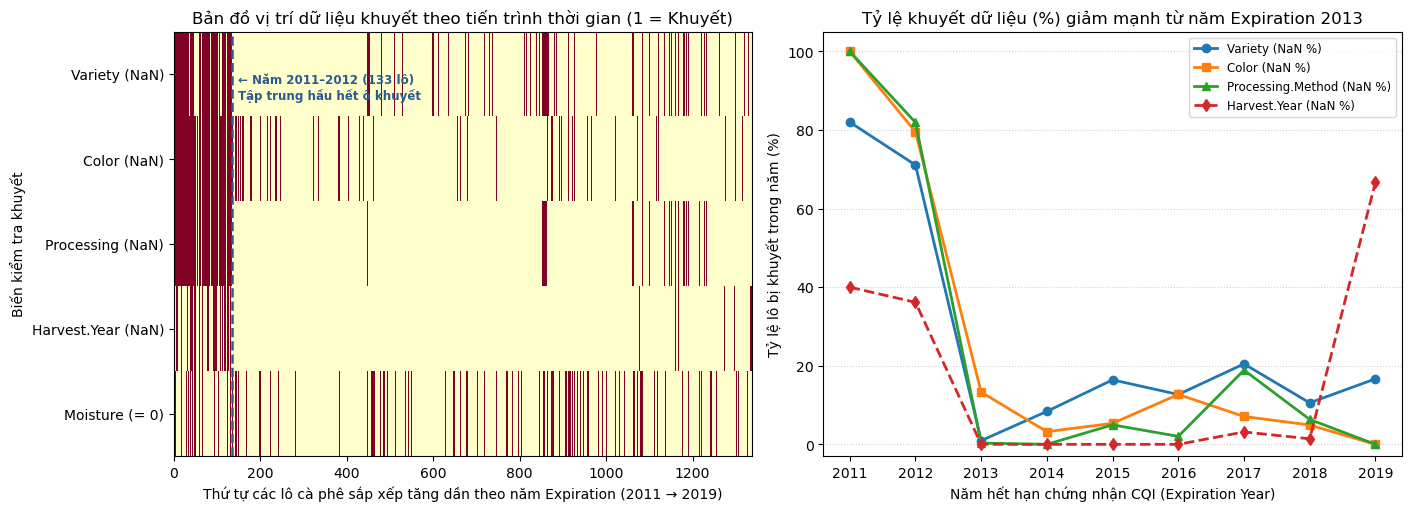

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")

# Biểu đồ 1: Heatmap vị trí dữ liệu khuyết (gồm cả Moisture==0) sắp xếp theo năm Expiration
ax = axes[0]
sorted_df = df_miss_check.sort_values(["exp_year", "REC_ID"]).reset_index(drop=True)
heatmap_data = pd.DataFrame({
    "Variety (NaN)": sorted_df["Variety"].isna().astype(int),
    "Color (NaN)": sorted_df["Color"].isna().astype(int),
    "Processing (NaN)": sorted_df["Processing.Method"].isna().astype(int),
    "Harvest.Year (NaN)": sorted_df["Harvest.Year"].isna().astype(int),
    "Moisture (= 0)": (sorted_df["Moisture"] == 0).astype(int),
})
im = ax.imshow(heatmap_data.T, aspect="auto", cmap="YlOrRd", interpolation="nearest")
ax.set_yticks(range(len(heatmap_data.columns)), heatmap_data.columns)
ax.set_xlabel("Thứ tự các lô cà phê sắp xếp tăng dần theo năm Expiration (2011 → 2019)")
ax.set_ylabel("Biến kiểm tra khuyết")
ax.set_title("Bản đồ vị trí dữ liệu khuyết theo tiến trình thời gian (1 = Khuyết)")

# Đánh dấu ranh giới năm 2012 -> 2013 trên trục X
n_2011_2012 = int((sorted_df["exp_year"] <= 2012).sum())
ax.axvline(n_2011_2012, color="#2B5C8F", linestyle="--", linewidth=1.8)
ax.text(n_2011_2012 + 15, 0.3, f"← Năm 2011–2012 ({n_2011_2012} lô)\nTập trung hầu hết ô khuyết", color="#2B5C8F", fontweight="bold", fontsize=8.5)

# Biểu đồ 2: Đường xu hướng tỷ lệ khuyết (%) theo năm Expiration
ax = axes[1]
years_plot = by_exp_year.index.astype(str)
ax.plot(years_plot, by_exp_year["Variety_miss_pct"], marker="o", linewidth=2, label="Variety (NaN %)")
ax.plot(years_plot, by_exp_year["Color_miss_pct"], marker="s", linewidth=2, label="Color (NaN %)")
ax.plot(years_plot, by_exp_year["Processing_miss_pct"], marker="^", linewidth=2, label="Processing.Method (NaN %)")
ax.plot(years_plot, by_exp_year["HarvestYear_miss_pct"], marker="d", linewidth=2, linestyle="--", label="Harvest.Year (NaN %)")
ax.set_title("Tỷ lệ khuyết dữ liệu (%) giảm mạnh từ năm Expiration 2013")
ax.set_xlabel("Năm hết hạn chứng nhận CQI (Expiration Year)")
ax.set_ylabel("Tỷ lệ lô bị khuyết trong năm (%)")
ax.set_ylim(-3, 105)
ax.grid(axis="y", linestyle=":", alpha=0.6)
ax.legend(fontsize=8.5)

plt.show()

#### d. Kế hoạch xử lý dữ liệu thiếu (Missing Data Handling Plan)

Dựa trên bằng chứng kiểm chứng ở trên, việc khuyết dữ liệu **không hoàn toàn ngẫu nhiên (MAR — phụ thuộc mạnh vào năm thu thập `Expiration` và Châu lục)**. Vì vậy, nếu xoá toàn bộ các dòng có `NaN` (`listwise deletion` làm mất `345/1.339` lô = `25,77%`, đặc biệt xoá gần sạch dữ liệu năm `2010–2011`) hoặc điền bằng `mode`/`mean` toàn cục sẽ gây thiên lệch nghiêm trọng. Nhóm thiết lập kế hoạch xử lý theo từng biến như sau:

| Biến / Bản ghi | Tỷ lệ thiếu / lỗi | Cơ chế khuyết phát hiện được | Cách xử lý trong phân tích (Q1–Q6) & Mô hình ML (Q2) | Lý do bảo vệ |
| :--- | :--- | :--- | :--- | :--- |
| **`REC_ID = 1310`** (`9` cột cảm quan = `0`) | `1` lô (`0,07%`) | Lỗi nhập liệu / giá trị giữ chỗ cho lô chưa có điểm cupping | **Loại bỏ khỏi mọi phân tích liên quan đến điểm cảm quan** (`df_eda` còn `1.338` lô) | Giữ lại sẽ làm méo trung bình, phương sai và tương quan Pearson |
| **`Country.of.Origin` & `Continent.of.Origin`** (`REC_ID = 1197`) | `1` lô (`0,07% < 5%`) | Bản ghi năm 2012 khuyết đồng thời cả 6 cột metadata | Giữ trong thống kê mô tả toàn mẫu; **loại bỏ dòng `REC_ID = 1197`** khi phân tích theo châu lục/quốc gia (Q1, Q4, Q5, Q6) | Chỉ chiếm `0,07%`, không thể suy diễn quốc gia từ điểm cảm quan |
| **`Harvest.Year`** | `60` lô (`4,48% < 5%`) | Tập trung ở các lô chấm giai đoạn đầu (`2011–2012` chiếm `50/60` lô thiếu năm) | • **Q2 (ML), Q4 (xu hướng năm), Q5 (nối FAOSTAT theo năm):** Loại bỏ các lô thiếu `Harvest.Year` (không suy diễn từ `Expiration` vì chênh lệch `Expiration - Harvest.Year` dao động từ `1` đến `3` năm).<br>• **Q1, Q3, Q6 (không dùng năm):** Giữ nguyên các lô này để không mất mẫu. | Đảm bảo độ chính xác của trục thời gian trong time-based split (Q2) và chuỗi thời gian (Q4, Q5) |
| **`Processing.Method`** | `170` lô (`12,70%`, ngưỡng `5–40%`) | Khuyết theo giai đoạn đầu (`100%` năm 2011, `81,9%` năm 2012) và cao hơn ở Châu Phi (`20,37%`) | • **Q1 (Natural vs Washed):** Chỉ lọc các lô có nhãn sơ chế xác định; kiểm tra độ nhạy theo châu lục.<br>• **Bảng Crosstab & Q2 (ML):** Tạo nhãn riêng `"Unknown"` (hoặc `SimpleImputer(strategy='constant', fill_value='missing')` trong `Pipeline`). | Điền bằng `mode` (`Washed / Wet`) sẽ làm sai lệch tới `12,7%` mẫu, đặc biệt bóp méo cơ cấu sơ chế của Châu Phi và Nam Mỹ |
| **`Variety`** | `226` lô (`16,88%`, ngưỡng `5–40%`) | Khuyết cao ở giai đoạn `2011–2012` và ở Châu Phi (`29,01%`) | Giữ thành hạng mục `"Unknown"` / xử lý trong `Pipeline` cho Q2 (ML); không xoá dòng | Giống cây không thể đoán chính xác từ quốc gia; tạo nhãn thiếu giữ được `226` lô |
| **`Color`** (gồm `218` `NaN` + `52` chuỗi `"None"`) | `218` `NaN` (`16,28%`) + `52` `"None"` (`3,88%`) | Khuyết cao ở giai đoạn `2011–2012`; nhóm thiếu `Color` có tỷ lệ `Moisture == 0` lên tới `39,45%` | Giữ `NaN` thành trạng thái thiếu riêng và giữ `"none"` là nhãn ghi nhận không màu; trong ML đóng gói qua `Pipeline` | Tránh nhập nhằng giữa ô bị bỏ trống (`NaN`) và ô được người chấm ghi chữ `"None"` |
| **`Moisture == 0.00`** | `264` lô (`19,73%`) | Khuyết ẩn (giá trị quy ước khi không đo độ ẩm), đi kèm tỷ lệ khuyết `Color` và `Harvest.Year` cao gấp đôi | • **Q3 (Đức Thịnh):** Tách/chuyển `Moisture == 0` thành `NaN` khi xác định vùng độ ẩm tối ưu và thực hiện kiểm tra độ bền (D6).<br>• **Q2 (ML):** Tạo thêm cờ chỉ báo `moisture_is_zero` hoặc thay `0` bằng `NaN` rồi `SimpleImputer(strategy='median')` bên trong `Pipeline` trên tập train. | Ngăn giá trị giả `0,00` kéo lệch trung bình độ ẩm và hệ số hồi quy/cây quyết định |

In [52]:
# TEST — Kiểm tra tính chính xác của mục 3.2.4 Missing data
assert int(df.isna().any(axis=1).sum()) == 345, "Phải có đúng 345 dòng thiếu ít nhất 1 cột trên df gốc"
assert int((~df.isna().any(axis=1)).sum()) == 994, "Phải có đúng 994 dòng đầy đủ cả 22 cột"
assert int(df["Country.of.Origin"].isna().sum()) == 1, "Chỉ có 1 dòng thiếu Country.of.Origin (REC_ID=1197)"
assert int(df["Continent.of.Origin"].isna().sum()) == 1, "Chỉ có 1 dòng thiếu Continent.of.Origin (REC_ID=1197)"
assert by_exp_year.loc[2011, "Processing_miss_pct"] == 100.0, "Năm Expiration 2011 thiếu 100% Processing.Method"
assert by_exp_year.loc[2011, "Color_miss_pct"] == 100.0, "Năm Expiration 2011 thiếu 100% Color"
print("Missing data checks passed")

Missing data checks passed


#### Nhận xét — Missing data

- **Bức tranh tổng thể về độ khuyết:** Trên `1.339` lô, chỉ có `6/22` cột xuất hiện `NaN` tường minh gồm `Variety` (`226` lô, `16,88%`), `Color` (`218` lô, `16,28%`), `Processing.Method` (`170` lô, `12,70%`), `Harvest.Year` (`60` lô, `4,48%`), và `Country.of.Origin` cùng `Continent.of.Origin` (cùng khuyết trên đúng `1` lô `REC_ID = 1197`, `0,07%`). Tổng cộng có `994` lô (`74,23%`) đầy đủ hoàn toàn và `345` lô (`25,77%`) khuyết ít nhất một cột.
- **Sự tồn tại của mẫu đồng khuyết (Co-missingness):** Các cột không khuyết độc lập nhau. Có tới `102` lô khuyết đồng thời cả 3 cột `Variety + Color + Processing.Method` (trong đó `62` lô có năm thu hoạch, `39` lô khuyết thêm `Harvest.Year`, và `1` lô `REC_ID = 1197` khuyết cả 6 cột). Ngoài ra, nhóm khuyết `Color` hoặc `Harvest.Year` có tỷ lệ `Moisture == 0.00` lên tới `38,33%–39,45%`, cao gấp hơn 2 lần so với nhóm có đủ thông tin (`15,89%–18,86%`).
- **Bằng chứng khẳng định dữ liệu khuyết KHÔNG ngẫu nhiên (MAR theo thời gian và châu lục):**
  - **Theo thời gian (`Expiration` year):** Trong `50` lô hết hạn năm `2011`, có tới **`100%` thiếu `Color`**, **`100%` thiếu `Processing.Method`**, **`82,0%` thiếu `Variety`** và **`40,0%` thiếu `Harvest.Year`**. Sang năm `2012` (`83` lô), tỷ lệ thiếu 4 cột này vẫn ở mức rất cao (`71,1%`, `79,5%`, `81,9%` và `36,1%`). Ngược lại, từ năm `2013` đến `2018`, tỷ lệ thiếu `Harvest.Year` giảm về gần `0%`, và tỷ lệ thiếu `Processing.Method` giảm xuống chỉ còn `0%–18,9%`. Điều này chứng minh dữ liệu thiếu chủ yếu do **thay đổi quy trình/biểu mẫu lưu trữ của CQI trước và sau năm 2013**.
  - **Theo địa lý (`Continent.of.Origin`):** Châu Phi có tỷ lệ khuyết `Variety` (`29,01%`) và `Processing.Method` (`20,37%`) cao hơn hẳn Bắc Mỹ (`10,09%` và `8,58%`).
  - **Hệ quả quan trọng:** Vì dữ liệu khuyết gắn chặt với thời gian và châu lục, việc điền khuyết bằng nhãn phổ biến nhất (`mode`) sẽ gán sai hàng loạt lô Châu Phi/Nam Mỹ và các lô năm `2011–2012` thành `Washed / Wet` hoặc `Caturra`. Do đó, giữ trạng thái `"Unknown"` cho biến phân loại và lọc có kiểm soát theo từng câu hỏi là phương án duy nhất không làm biến dạng kết luận.

### 3.2.5. Relationships
*(Tùng Hiếu — `feat/eda-categorical`)*

#### Mẫu phân tích và `total_9`

`df_eda` là bản sao có `total_9` của `df`, bỏ riêng `REC_ID=1310` theo quy ước nhóm vì cả 9 điểm cảm quan đều bằng 0. Mẫu gồm cả Arabica và Robusta. Hai dòng 721 và 742 cùng các giá trị ngoại lệ còn lại được giữ trong EDA.

`total_9` là tổng 9 thuộc tính trong `SCORE_COLS` (thang 0–90). Một thuộc tính thiếu làm tổng điểm thiếu.

In [53]:
df_eda = add_total_score(df).loc[lambda rows: rows["REC_ID"].ne(1310)].copy()
physical_cols = ["Moisture", "Quakers", "Category.One.Defects", "Category.Two.Defects"]
relationship_cols = [*SCORE_COLS, *physical_cols, "total_9"]
print(f"Số lô trước và sau khi lọc: {len(df):,} → {len(df_eda):,}")
display_centered_table(df_eda["Species"].value_counts(dropna=False).rename_axis("Species").reset_index(name="n_lots").rename(columns={"n_lots": "Number of coffee lots"}))
display_centered_table(pd.DataFrame({
    "missing": df_eda[physical_cols].isna().sum(),
    "zero": df_eda[physical_cols].eq(0).sum(),
}).rename_axis("variable").reset_index())

Số lô trước và sau khi lọc: 1,339 → 1,338


,Species,Number of coffee lots
0,Arabica,1310
1,Robusta,28


,variable,missing,zero
0,Moisture,0,264
1,Quakers,0,1244
2,Category.One.Defects,0,1136
3,Category.Two.Defects,0,373


#### Correlation heatmaps và scatter plots

Tính Pearson và Spearman trên các quan sát có đủ dữ liệu cho từng cặp biến. Bảng `pairwise_n` cho biết mẫu số. `total_9` chứa chính các điểm thành phần, nên khi diễn giải cần xét mối liên hệ do công thức tổng tạo ra.

,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Moisture,Quakers,Category.One.Defects,Category.Two.Defects,total_9
Aroma,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Flavor,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Aftertaste,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Acidity,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Body,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Balance,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Uniformity,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Clean.Cup,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Sweetness,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338
Moisture,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338,1338


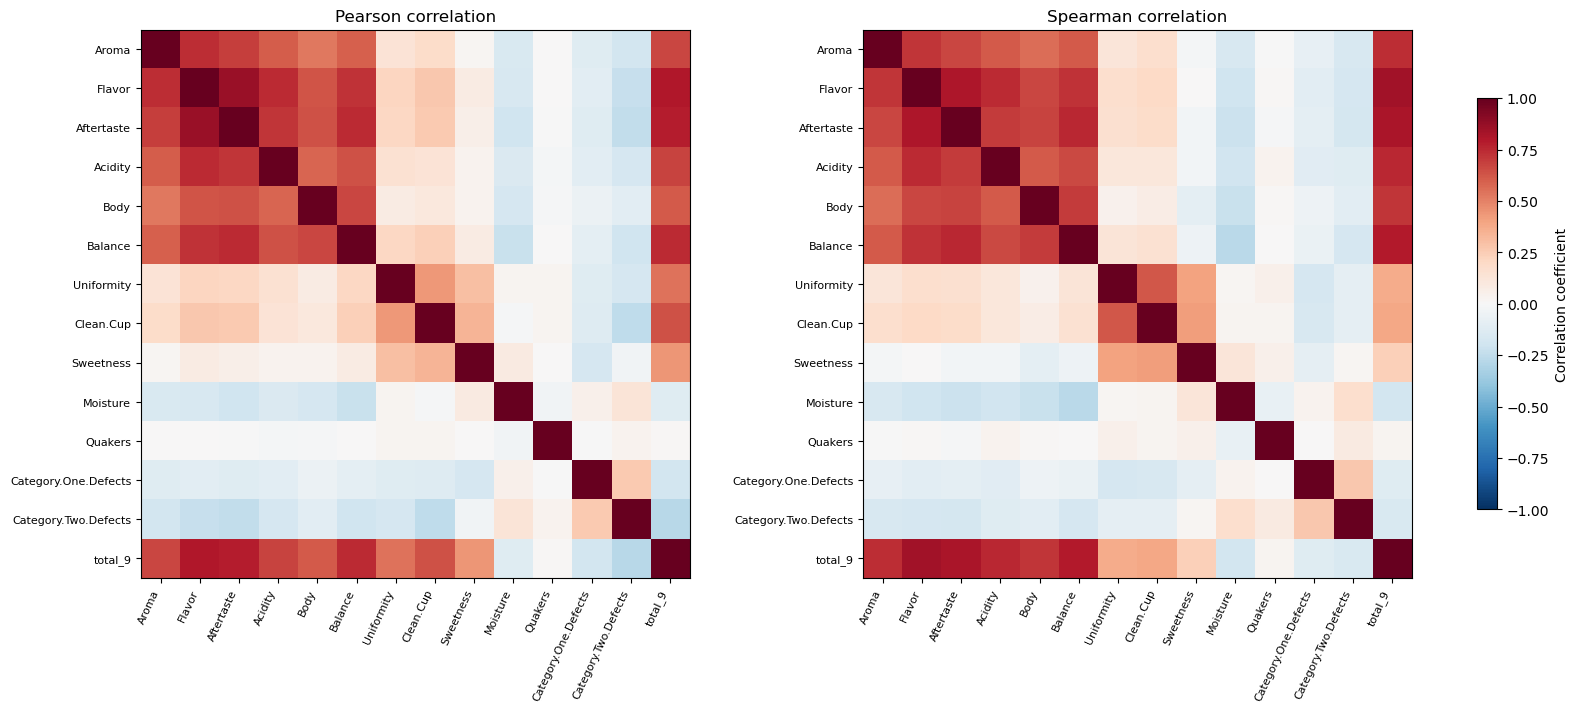

,variable_1,variable_2,Number of coffee lots,pearson,spearman
13,Flavor,Aftertaste,1338,0.860,0.809
24,Flavor,total_9,1338,0.798,0.836
35,Aftertaste,total_9,1338,0.784,0.815
14,Flavor,Acidity,1338,0.746,0.744
27,Aftertaste,Balance,1338,0.746,0.753
62,Balance,total_9,1338,0.743,0.791
0,Aroma,Flavor,1338,0.740,0.715
16,Flavor,Balance,1338,0.720,0.725
25,Aftertaste,Acidity,1338,0.716,0.697
1,Aroma,Aftertaste,1338,0.694,0.668


In [54]:
relationship_numeric = df_eda[relationship_cols]
available = relationship_numeric.notna().astype(int)
pairwise_n = available.T @ available
correlations = {
    method: relationship_numeric.corr(method=method)
    for method in ("pearson", "spearman")
}
display_centered_table(pairwise_n)

fig, axes = plt.subplots(1, 2, figsize=(16, 7), layout="constrained")
for ax, (method, matrix) in zip(axes, correlations.items()):
    image = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(matrix)), matrix.columns, rotation=65, ha="right", fontsize=8)
    ax.set_yticks(range(len(matrix)), matrix.index, fontsize=8)
    ax.set_title(f"{method.title()} correlation")
fig.colorbar(image, ax=axes, shrink=0.75, label="Correlation coefficient")
plt.show()

row_idx, col_idx = np.triu_indices(len(relationship_cols), k=1)
correlation_pairs = pd.DataFrame({
    "variable_1": relationship_numeric.columns[row_idx],
    "variable_2": relationship_numeric.columns[col_idx],
    "n_lots": pairwise_n.to_numpy()[row_idx, col_idx],
    **{method: matrix.to_numpy()[row_idx, col_idx] for method, matrix in correlations.items()},
})
display_centered_table(correlation_pairs.sort_values("pearson", key=lambda values: values.abs(), ascending=False).head(10).round(3).rename(columns={"n_lots": "Number of coffee lots"}))

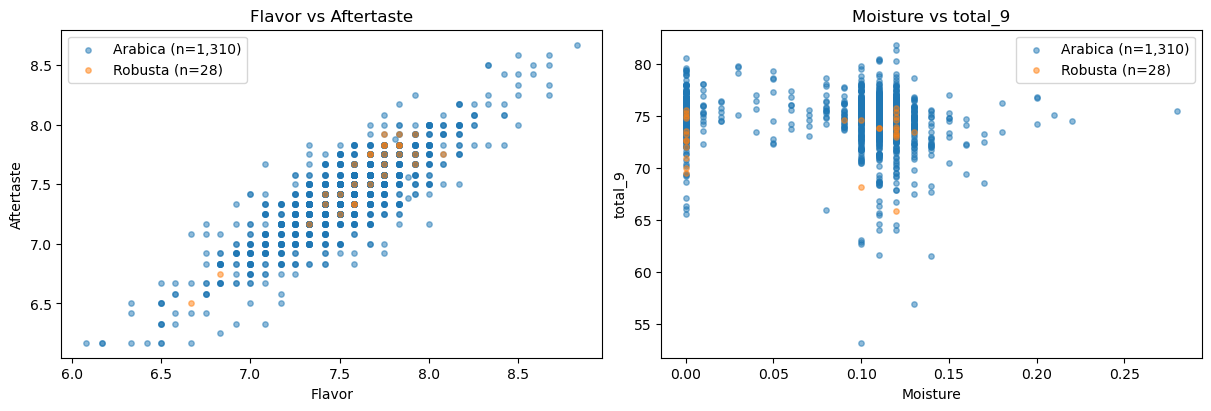

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for ax, (x, y) in zip(axes, [("Flavor", "Aftertaste"), ("Moisture", "total_9")]):
    for species, rows in df_eda.groupby("Species"):
        points = rows[[x, y]].dropna()
        ax.scatter(points[x], points[y], s=15, alpha=0.5, label=f"{species} (n={len(points):,})")
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(f"{x} vs {y}")
    ax.legend()
plt.show()

#### `Species` và `Country.of.Origin`

So sánh số lô và median `total_9` theo `Species`. Bảng quốc gia dùng tên chưa gộp và chỉ giữ các quốc gia có ít nhất 20 lô có `total_9` hợp lệ.

In [56]:
valid_score_lots = df_eda.dropna(subset=["total_9"])
species_score_summary = valid_score_lots.groupby("Species")["total_9"].agg(
    n_lots="size", median_total_9="median",
)
country_score_summary = (
    valid_score_lots.groupby("Country.of.Origin")["total_9"]
    .agg(n_lots="size", median_total_9="median")
    .query("n_lots >= 20")
    .sort_values("median_total_9", ascending=False)
)
display_centered_table(species_score_summary.reset_index().round(2).rename(columns={"n_lots": "Number of coffee lots"}))
display_centered_table(country_score_summary.reset_index().round(2).rename(columns={"n_lots": "Number of coffee lots"}))

,Species,Number of coffee lots,median_total_9
0,Arabica,1310,75.00
1,Robusta,28,73.66


,Country.of.Origin,Number of coffee lots,median_total_9
0,Ethiopia,44,77.25
1,Kenya,25,76.83
2,Colombia,183,75.68
3,Uganda,36,75.55
4,El Salvador,21,75.50
5,Indonesia,20,75.37
6,Costa Rica,51,75.34
7,Thailand,32,75.13
8,Guatemala,181,75.07
9,United States,87,75.00


#### Crosstab `Continent.of.Origin` × `Processing.Method`

Bảng số lô dùng nhãn hiển thị `Unknown` cho giá trị thiếu. Bảng tỷ lệ theo hàng chỉ dùng lô có đủ cả hai nhãn. Cột `n_known` là mẫu số của từng châu lục.

In [57]:
continent_col = "Continent.of.Origin"
method_col = "Processing.Method"
crosstab_counts = pd.crosstab(
    df_eda[continent_col].fillna("Unknown"),
    df_eda[method_col].fillna("Unknown"),
    margins=True,
    margins_name="Total",
)
known_processing = df_eda.dropna(subset=[continent_col, method_col])
crosstab_pct = pd.crosstab(
    known_processing[continent_col], known_processing[method_col], normalize="index",
).mul(100)
crosstab_pct.insert(0, "n_known", known_processing.groupby(continent_col).size())
print(f"Số lô đủ cả hai nhãn: {len(known_processing):,}")
display_centered_table(crosstab_counts.rename_axis(columns=None).reset_index())
display_centered_table(crosstab_pct.rename_axis(columns=None).reset_index().round(2))

Số lô đủ cả hai nhãn: 1,169


,Continent.of.Origin,Natural / Dry,Other,Pulped natural / honey,Semi-washed / Semi-pulped,Unknown,Washed / Wet,Total
0,Africa,27,0,0,2,33,100,162
1,Asia,32,17,5,14,25,89,182
2,North America,91,8,2,16,57,490,664
3,Oceania,0,0,0,0,0,1,1
4,South America,108,1,7,24,53,135,328
5,Unknown,0,0,0,0,1,0,1
6,Total,258,26,14,56,169,815,1338


,Continent.of.Origin,n_known,Natural / Dry,Other,Pulped natural / honey,Semi-washed / Semi-pulped,Washed / Wet
0,Africa,129,20.93,0.00,0.00,1.55,77.52
1,Asia,157,20.38,10.83,3.18,8.92,56.69
2,North America,607,14.99,1.32,0.33,2.64,80.72
3,Oceania,1,0.00,0.00,0.00,0.00,100.00
4,South America,275,39.27,0.36,2.55,8.73,49.09


In [58]:
# TEST
assert set(df["REC_ID"]) - set(df_eda["REC_ID"]) == {1310}
assert len(df_eda) == len(df) - 1
assert "total_9" not in df.columns
assert {721, 742}.issubset(set(df_eda["REC_ID"]))
assert df_eda["total_9"].isna().equals(df_eda[SCORE_COLS].isna().any(axis=1))
assert crosstab_counts.loc["Total", "Total"] == len(df_eda)
assert crosstab_pct["n_known"].sum() == len(known_processing)
assert np.allclose(crosstab_pct.drop(columns="n_known").sum(axis=1), 100)
assert country_score_summary["n_lots"].ge(20).all()
print("Relationship checks passed")

Relationship checks passed


#### Nhận xét — Relationships

- **Correlation heatmaps:** Các cặp trong hai ma trận đều có 1.338 lô. `Flavor` và `Aftertaste` có tương quan dương mạnh theo cả Pearson là 0,860 và Spearman là 0,809. Scatter plot cho thấy dải điểm đi lên rõ. `Clean.Cup` và `total_9` có chênh lệch tuyệt đối giữa hai hệ số khoảng 0,251, lớn nhất trong các cặp gồm hai biến khác nhau. Mức chênh này cho thấy độ mạnh của liên hệ thay đổi tùy cách đo. Vì `Clean.Cup` là một phần của `total_9`, tương quan giữa chúng có sẵn một phần từ công thức tính tổng.
- **`Moisture` và `total_9`:** Scatter plot cho thấy `total_9` phân tán rộng ở cùng mức `Moisture`, đặc biệt ở vùng 0,10–0,13. Có một cụm dọc tại 0 với 264 lô. Pearson khoảng −0,121 và Spearman khoảng −0,185, cho thấy liên hệ âm yếu trong mẫu gộp. Cụm 264 lô ở mức 0 chiếm gần một phần năm mẫu. Nếu các số 0 là giá trị quy ước thay cho số đo còn thiếu, hệ số hiện tại có thể thay đổi khi xử lý lại nhóm này.
- **`Species` và điểm tổng:** Median `total_9` của Arabica là 75,00 trên 1.310 lô, còn Robusta là 73,66 trên 28 lô. Chênh lệch mô tả khoảng 1,34 điểm. Do Arabica chiếm gần 98% mẫu Relationships, kết quả gộp chủ yếu phản ánh các lô Arabica. Với 28 lô, median Robusta dựa trên ít quan sát hơn nhiều so với Arabica. Chênh lệch 1,34 điểm vì vậy được trình bày như một so sánh mô tả trong mẫu.
- **Crosstab:** Bảng tỷ lệ dùng 1.169 lô có đủ `Continent.of.Origin` và `Processing.Method`. Trong số các lô có đủ nhãn, Washed / Wet chiếm 80,72% ở North America, tương ứng 490 trên 607 lô, và 77,52% ở Africa, tương ứng 100 trên 129 lô. South America có tỷ lệ Natural / Dry là 39,27%, tương ứng 108 trên 275 lô, cao hơn các châu lục còn lại trong bảng. Oceania có tỷ lệ Washed / Wet là 100% dựa trên đúng một lô. Bảng số lô còn cho thấy 169 lô thiếu `Processing.Method`, trong đó có 33/162 lô ở Africa. Ví dụ, tỷ lệ 77,52% của Africa được tính trên 129 lô biết phương pháp sơ chế, trong khi châu lục này có tổng cộng 162 lô. Khi so sánh với North America, cần đọc cả tỷ lệ và số lô thiếu vì cơ cấu của những lô thiếu nhãn chưa xác định được.
- **Median theo `Country.of.Origin`:** Trong 16 quốc gia đạt ngưỡng 20 lô, Ethiopia có median cao nhất với 77,25 điểm trên 44 lô, tiếp theo là Kenya với 76,83 điểm trên 25 lô. Nicaragua có median thấp nhất với 73,54 điểm trên 26 lô. Số lô chênh đáng kể giữa các nước, từ 20 lô ở Indonesia đến 236 lô ở Mexico. Thứ hạng này áp dụng cho các lô CQI trong mẫu và có thể phản ánh cả khác biệt về loài hoặc cách sơ chế giữa các nước. So sánh các lô cùng `Species` và `Processing.Method` sẽ giúp kiểm tra xem chênh lệch theo xuất xứ còn rõ đến mức nào.

### 3.2.6. Summary

*(Tùng Hiếu — `feat/eda-categorical`)*

Bảng gốc có **1.339 bản ghi lô cà phê và 22 cột**. Các thống kê về cơ cấu mẫu và dữ liệu thiếu dùng toàn bộ 1.339 lô. Phân tích điểm cảm quan và Relationships dùng **1.338 lô** sau khi tách bản ghi có cả chín điểm bằng 0. Từng phép so sánh bên dưới dùng mẫu số phù hợp với các biến cần phân tích.

#### a. Năm quan sát chính

1. **Mẫu tập trung vào Arabica và một số nước xuất xứ.** Trong 1.339 lô, có 1.311 lô Arabica, chiếm 97,91%. Mexico, Colombia và Guatemala có tổng cộng 600 lô, chiếm 44,81% mẫu. Vì vậy, kết quả tính chung chịu ảnh hưởng nhiều hơn từ các nhóm đông lô. Chẳng hạn, median `total_9` của Robusta là 73,66 điểm trên 28 lô, còn Arabica là 75,00 điểm trên 1.310 lô trong Relationships. Chênh lệch này mô tả mẫu CQI và cần được đọc cùng cỡ mẫu của từng loài.
2. **Một bản ghi toàn điểm 0 làm thay đổi phân phối, còn ba thuộc tính có hiệu ứng trần điểm.** Lô `REC_ID = 1310` có cả chín điểm cảm quan bằng 0. Sau khi tách lô này, median `total_9` là 75,00 điểm và 50% số lô ở giữa nằm trong khoảng 73,82–75,92 điểm. Trong 1.338 lô còn lại, tỷ lệ đạt điểm 10 lần lượt là 86,10% ở `Uniformity`, 91,11% ở `Clean.Cup` và 91,03% ở `Sweetness`. IQR của ba cột đều bằng 0, nên quy tắc 1,5 IQR có thể gắn nhãn ngoại lệ cho mọi điểm dưới 10. Vì vậy, cần xem phân phối và cách chấm từng thuộc tính trước khi áp dụng ngưỡng lọc.
3. **Giá trị độ ẩm bằng 0 ảnh hưởng đáng kể đến thống kê độ ẩm.** Có 264 trên 1.338 lô có `Moisture = 0`, tương đương 19,73%. Mean độ ẩm khoảng 8,8% trên toàn mẫu Relationships và 11,0% khi xét riêng 1.074 lô có độ ẩm dương. Các giá trị 0 cần được xem xét như giá trị có thể đại diện cho số đo thiếu. Các cột đếm lỗi hạt cũng lệch phải mạnh, nên việc loại tất cả lô bị gắn cờ ngoại lệ có thể làm mất những lô quan trọng để tìm hiểu mối liên hệ giữa lỗi hạt và điểm cảm quan.
4. **Dữ liệu thiếu tập trung theo cột, thời gian và xuất xứ.** Có 345 trên 1.339 lô thiếu ít nhất một trường, tương đương 25,77%. Ba cột thiếu nhiều nhất là `Variety` với 226 lô, `Color` với 218 lô và `Processing.Method` với 170 lô. Trong 50 lô có năm hết hạn chứng nhận là 2011, tất cả đều thiếu nhãn sơ chế. Ở mẫu Relationships, tỷ lệ thiếu nhãn sơ chế của Africa là 33 trên 162 lô, cao hơn North America với 57 trên 664 lô. Nếu bỏ toàn bộ các dòng thiếu, thành phần của mẫu có thể thay đổi theo cả thời gian lẫn xuất xứ. Các bảng cho thấy mẫu hình thiếu. Nguyên nhân ghi nhận dữ liệu vẫn cần được xác minh từ nguồn.
5. **Mối liên hệ phụ thuộc vào biến và nhóm được so sánh.** `Flavor` và `Aftertaste` có tương quan dương mạnh, với Pearson là 0,860 và Spearman là 0,809. `Moisture` và `total_9` có liên hệ âm yếu trong mẫu gồm cả các giá trị độ ẩm bằng 0. Trong 1.169 lô đủ nhãn châu lục và sơ chế, Washed / Wet chiếm 490 trên 607 lô ở North America, tương đương 80,72%, còn Natural / Dry chiếm 108 trên 275 lô ở South America, tương đương 39,27%. Sự khác biệt về cơ cấu sơ chế theo xuất xứ là lý do cần xem xét xuất xứ khi so sánh điểm giữa các phương pháp.

#### b. Kế hoạch tiền xử lý

| Vấn đề | Cách xử lý dự kiến và lý do |
|---|---|
| Bản ghi và khóa định danh | Giữ bảng gốc để truy vết bằng `REC_ID`. Tách lô `1310` khi phân tích điểm. Hai lô `721` và `742` giống nhau ở 21 cột ngoài ID, nên giữ trong EDA và kiểm tra độ nhạy khi bỏ một bản ghi. Nếu dùng cho ML, tránh để hai bản ghi này rơi vào hai tập đánh giá khác nhau. |
| Điểm cảm quan và lỗi hạt | Giữ chín thuộc tính để tính `total_9`. Khi cần so sánh hồ sơ cảm quan, kiểm tra độ nhạy khi chỉ dùng sáu thuộc tính ít bị trần điểm hơn. Dùng các ngưỡng IQR để đánh dấu lô nhiều lỗi hạt và so sánh kết quả giữa các cách lọc. |
| Độ ẩm bằng 0 | Giữ các giá trị 0 trong bảng gốc và tạo cờ riêng. Khi nghiên cứu độ ẩm, đối chiếu kết quả trên mẫu gộp với mẫu chỉ có `Moisture > 0` để xem kết luận nhạy đến đâu với cách xử lý 264 giá trị này. |
| Nhãn phân loại thiếu và nhóm hiếm | Giữ 52 giá trị `Color = "None"` tách biệt với ô trống. Dùng `Unknown` để thể hiện số lô thiếu nhãn trong bảng đếm. Khi tính tỷ lệ sơ chế, ghi số lô có đủ nhãn làm mẫu số. Dùng `Other (rare)` cho bảng trình bày khi cần, đồng thời giữ cột nhãn chi tiết để lọc và nối dữ liệu. |
| Khóa quốc gia và năm thu hoạch | Chuẩn hoá tên quốc gia và lưu năm thu hoạch dưới dạng số nguyên cho phép thiếu. Khi ghép FAOSTAT, dùng nhãn quốc gia chưa gộp và chỉ nối các lô có đủ khóa. Báo số lô khớp, không khớp và có khóa nhưng thiếu sản lượng để xác định phạm vi phân tích. |

#### c. Các hướng phân tích từ kết quả EDA

- **Phương pháp sơ chế và điểm cảm quan.** So sánh `total_9` giữa các phương pháp trên các lô có nhãn sơ chế. Vì cơ cấu sơ chế khác nhau theo địa lý, kiểm tra xem chênh lệch điểm còn rõ đến đâu khi so sánh trong cùng nhóm xuất xứ hoặc loài.
- **Độ ẩm, lỗi hạt và điểm cảm quan.** Kiểm tra mối liên hệ với `total_9` trên các lô có độ ẩm dương và so với kết quả trên toàn mẫu Relationships. Đối chiếu các cách giữ hoặc lọc lô nhiều lỗi để xem phát hiện có bền vững không.
- **Sản lượng và điểm cảm quan theo quốc gia–năm.** Ghép sản lượng cà phê nhân xanh từ FAOSTAT để xem sản lượng liên hệ thế nào với điểm của các lô CQI. Khi nhiều lô dùng chung một giá trị sản lượng, cần tính đến việc các lô thuộc cùng quốc gia–năm chia sẻ thông tin đó và báo rõ số lô quan sát được trong từng nhóm.
- **Hồ sơ cảm quan và hiệu ứng trần điểm.** So sánh kết quả khi dùng đủ chín thuộc tính với khi chỉ dùng sáu thuộc tính có độ phân tán cao hơn. Phép đối chiếu này cho biết ba cột thường đạt điểm tối đa ảnh hưởng đến cách phân biệt các lô đến mức nào.


---
✅ **Trước khi commit:** *Kernel → Restart & Run All*. Mọi ô `# TEST` phải chạy qua, mọi ô ✍️ phải có câu trả lời.

---
# Tài liệu tham khảo

[1] RealDealAdamP. *Coffee Quality with Locations of Origin*. Kaggle. https://www.kaggle.com/datasets/adampq/coffee-quality-with-locations-of-origin

[2] Coffee Quality Institute. https://www.coffeeinstitute.org

[3] Creative Commons. *Attribution-ShareAlike 4.0 International (CC BY-SA 4.0)*. https://creativecommons.org/licenses/by-sa/4.0/

[4] J. LeDoux. *coffee-quality-database*. GitHub. https://github.com/jldbc/coffee-quality-database

[5] J. VanderPlas. *Python Data Science Handbook*. O'Reilly, 2016.

[6] D. Volpatto. *Coffee Quality database from CQI*. Kaggle. https://www.kaggle.com/datasets/volpatto/coffee-quality-database-from-cqi

[7] F. Boyar. *Coffee Quality Data (CQI May-2023)*. Kaggle. https://www.kaggle.com/datasets/fatihb/coffee-quality-data-cqi

[8] Specialty Coffee Association. *Protocols & Best Practices*. https://sca.coffee/research/protocols-best-practices